<table style="width: 100%;">
  <tr>
    <td style="text-align: left; vertical-align: middle;">
        <h1 style="margin: 0;">Deep Learning's Assignment 1</h1>
        <h4 style="margin: 0;">Prof. Bahrak</h4>
        <h4 style="margin: 0;">Authors: Erfan Ahmadi, Mohammad Ali Olama</h4>
        <h4 style="margin: 0;">[Group work]</h4>
    </td>
    <td style="text-align: right; vertical-align: middle;">
      <img src="https://media.porsline.ir/images/1642313491sktwifppujekhvh" alt="CC" width="1000">
    </td>
  </tr>
</table>



# Import libraries


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense, Dropout, InputLayer, Flatten
from tensorflow.keras.regularizers import l2
from sklearn.metrics import confusion_matrix
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
tf.random.set_seed(42)

# Q1

First we load the requested dataset from keras:

In [ ]:
# Load the Fashion-MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


let's plot some samples from dataset:

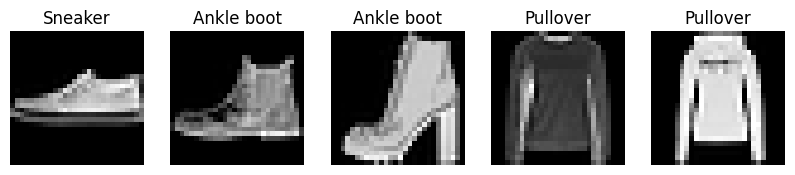

In [ ]:
# Number of samples to display
num_samples = 5

# Generate random indices for the samples
random_indices = np.random.choice(len(x_train), size=num_samples, replace=False)

# Plot the samples
plt.figure(figsize=(num_samples*2, 4))
for i, index in enumerate(random_indices):
    plt.subplot(1, num_samples, i + 1)
    plt.imshow(x_train[index], cmap='gray')
    plt.title(class_names[y_train[index]])
    plt.axis('off')
plt.show()


Since each pixel is an int in range 0 , 255, it is good to convert it to float (for high precision cumputations) and also normalize the range of density pixels:

In [ ]:
# Normalize pixel values to be between 0 and 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

##  Q1.1
First lets create our model:

In [ ]:
# Define the model
model = keras.Sequential([
    InputLayer(shape=[28,28]),
    Flatten(),
    Dense(100, activation="relu", kernel_regularizer=l2(0.0001))  ,   # L2 regularization
    Dropout(0.3),
    Dense(10, activation="softmax") #output layer
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 100)                 │          78,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile the model
model.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)

# Train the model
history = model.fit(x_train, y_train, epochs=50, batch_size=64, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(x_test, y_test, verbose=1)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Epoch 1/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7043 - loss: 0.8578 - val_accuracy: 0.8468 - val_loss: 0.4641
Epoch 2/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8341 - loss: 0.4858 - val_accuracy: 0.8572 - val_loss: 0.4264
Epoch 3/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8502 - loss: 0.4440 - val_accuracy: 0.8638 - val_loss: 0.4023
Epoch 4/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8583 - loss: 0.4232 - val_accuracy: 0.8679 - val_loss: 0.3981
Epoch 5/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8639 - loss: 0.4055 - val_accuracy: 0.8731 - val_loss: 0.3872
Epoch 6/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8670 - loss: 0.3964 - val_accuracy: 0.8727 - val_loss: 0.3817
Epoch 7/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8702 - loss: 0.3862 - val_accuracy: 0.8708 - val_loss: 0.3850
Epoch 8/50
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8734 - loss: 0.3842 - val_accuracy: 0.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


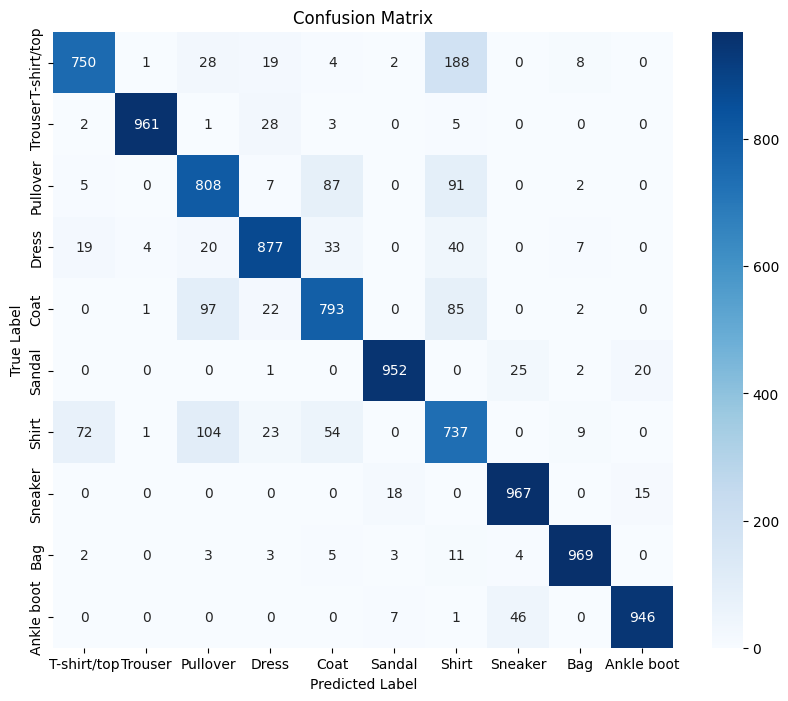

In [ ]:
# confusion matrix

# Get predictions for the test set
y_pred = np.argmax(model.predict(x_test), axis=1)

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# plot cm matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
# for each class, find the most confused class:

def most_confused_classes(cm , class_names):
  most_confused_classes = {}
  for i in range(len(class_names)):
      cm_row = cm[i, :]
      cm_row[i] = 0   # Exclude correct classifications
      most_confused_class_index = np.argmax(cm_row)
      most_confused_classes[class_names[i]] = class_names[most_confused_class_index]

  print("Most confused classes:")
  for class_name, confused_class in most_confused_classes.items():
      print(f"{class_name}: {confused_class}")
  return most_confused_classes

a = most_confused_classes(cm , class_names)

Most confused classes:
T-shirt/top: Shirt
Trouser: Dress
Pullover: Shirt
Dress: Shirt
Coat: Pullover
Sandal: Sneaker
Shirt: Pullover
Sneaker: Sandal
Bag: Shirt
Ankle boot: Sneaker


### Purpose of the Dropout Layer

The dropout layer is a regularization technique used to prevent overfitting in neural networks. During training, dropout randomly "drops out" (sets to zero) a fraction of neurons in a layer, along with their connections. This helps the model generalize better by reducing its reliance on specific neurons and forcing it to learn more robust features.

By randomly deactivating neurons, dropout reduces the risk of the model memorizing the training data and encourages it to learn generalized patterns. (reduce risk of overfitting)

Dropout effectively trains multiple sub-networks by randomly altering the architecture during training, resulting in an ensemble-like effect that improves performance.

### Implementation:
- Dropout is typically used in fully connected layers but can also be applied to other layers.
- During training, a dropout rate (e.g., 0.5) specifies the fraction of neurons to deactivate.
- During inference, no neurons are dropped, but their activations are scaled to account for the dropout applied during training.


![Image](https://production-media.paperswithcode.com/methods/Screen_Shot_2020-05-23_at_6.19.24_PM.png)

# Q1.2

In [ ]:
# Define Model 1: 128-node dense layer without dropout or regularization
def create_model_1():
    model = keras.Sequential([
        InputLayer(shape=[28,28]),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(10, activation='softmax')
    ])
    return model

# Define Model 2: 48-node dense layer with L2 regularization and Dropout
def create_model_2():
    model = keras.Sequential([
        InputLayer(shape=[28,28]),
        Flatten(),
        Dense(48, activation='relu', kernel_regularizer=l2(0.0001)),
        Dropout(0.2),
        Dense(10, activation='softmax')
    ])
    return model


# Compile and train models
def train_model(model, model_name):
    print("**************  " + model_name + "  **************")
    model.compile(optimizer='sgd',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    history = model.fit(x_train, y_train, epochs=40, batch_size=64, validation_split=0.2)
    loss, accuracy = model.evaluate(x_test, y_test, verbose=1)
    print(f"Test Loss: {loss:.4f}")
    print(f"Test Accuracy: {accuracy:.4f}")
    return history, loss, accuracy

# Train both models
model_1 = create_model_1()
model_2 = create_model_2()
history_1 , loss_1 , acc_1 = train_model(model_1, "Model 1")
history_2 , loss_2 , acc_2 = train_model(model_2, "Model 2")



**************  Model 1  **************
Epoch 1/40
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5893 - loss: 1.3024 - val_accuracy: 0.7767 - val_loss: 0.6747
Epoch 2/40
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7855 - loss: 0.6447 - val_accuracy: 0.8083 - val_loss: 0.5744
Epoch 3/40
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8142 - loss: 0.5586 - val_accuracy: 0.8197 - val_loss: 0.5298
Epoch 4/40
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8266 - loss: 0.5166 - val_accuracy: 0.8257 - val_loss: 0.5032
Epoch 5/40
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8350 - loss: 0.4905 - val_accuracy: 0.8317 - val_loss: 0.4847
Epoch 6/40
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8397 - loss: 0.4721 - val_accuracy: 0.8372 - val_loss: 0.4709
Epoch 7/40
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8432 - loss: 0.4578 - val_accuracy: 0.8407 - val_loss: 0.4602
Epoch 8/40
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 

In [ ]:
#  a function to plot histogram of weight for input layer and first hidden layer of a model

import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

def plot_weight_histograms(model , model_name):
    layer_weights = [layer.get_weights()[0] for layer in model.layers if isinstance(layer, Dense)]

    input_layer_weights = layer_weights[0].flatten()
    hidden_layer_weights = layer_weights[1].flatten()

    # Create subplots
    fig = make_subplots(rows=1, cols=2, subplot_titles=("Input Layer Weights of " + model_name, "First Hidden Layer Weights of " + model_name))

    # Add histograms to the subplots
    fig.add_trace(go.Histogram(x=input_layer_weights, nbinsx=50, name='Input Layer'), row=1, col=1)
    fig.add_trace(go.Histogram(x=hidden_layer_weights, nbinsx=50, name='First Hidden Layer'), row=1, col=2)

    # Update layout for better visualization
    fig.update_layout(title_text="Weight Histograms", barmode='overlay')
    fig.show()

# Example usage (assuming 'model' is your trained Keras model):
plot_weight_histograms(model_1 , "Model 1")
plot_weight_histograms(model_2 , "Model 2")


# Stochastic Gradient Descent (SGD)

## Advantages of SGD
- Faster updates compared to batch gradient descent.
- Works well with large datasets.

## Disadvantages
- High variance in updates can lead to instability.
- Requires careful tuning of the learning rate.
![Gradient Descent](https://ml-explained.com/_ipx/sizes_xs:320px%20md:768px%20lg:1024px,w_1536,f_png/articles/gradient-descent-explained/variations_comparison.png)  



## Q1.3

In [ ]:
# Define a function to train the model with different optimizers
def train_with_optimizer(optimizer_name):
    print("**************  " + optimizer_name + "  **************")
    model = keras.Sequential([
        InputLayer(shape=[28,28]),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer=optimizer_name,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    history = model.fit(x_train, y_train, epochs=30, batch_size=128, validation_split=0.2, verbose=0)
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
    return model , history, loss, accuracy

# Train the model with different optimizers
optimizers = ["Nadam", "Adam", "RMSprop"]
histories = []
models = []
losses = []
accuracies = []

for optimizer in optimizers:
    model, history, loss, accuracy = train_with_optimizer(optimizer)
    models.append(model)
    histories.append(history)
    losses.append(loss)
    accuracies.append(accuracy)
    print(f"Optimizer: {optimizer}, Loss: {loss:.4f}, Accuracy: {accuracy:.4f}")


**************  Nadam  **************
Optimizer: Nadam, Loss: 0.3968, Accuracy: 0.8759
**************  Adam  **************
Optimizer: Adam, Loss: 0.3994, Accuracy: 0.8763
**************  RMSprop  **************
Optimizer: RMSprop, Loss: 0.4694, Accuracy: 0.8692


In [ ]:
def plot(histories , param1 , param2, label1 , label2 , legend):
  # Create a figure with 2 subplots
  fig, axes = plt.subplots(1, 2, figsize=(15, 5))

  # Plot training accuracy
  for i, history in enumerate(histories):
      axes[0].plot(history.history[param1], label=legend[i])
  axes[0].set_xlabel('Epochs')
  axes[0].set_ylabel(label1)
  axes[0].set_title(label1 + ' Over Time')
  axes[0].legend()
  axes[0].grid(True)

  # Plot validation accuracylabel1
  for i, history in enumerate(histories):
      axes[1].plot(history.history[param2], label=legend[i])
  axes[1].set_xlabel('Epochs')
  axes[1].set_ylabel(label2)
  axes[1].set_title(label2 + ' Over Time')
  axes[1].legend()
  axes[1].grid(True)

  # Adjust layout for better spacing
  plt.tight_layout()
  plt.show()


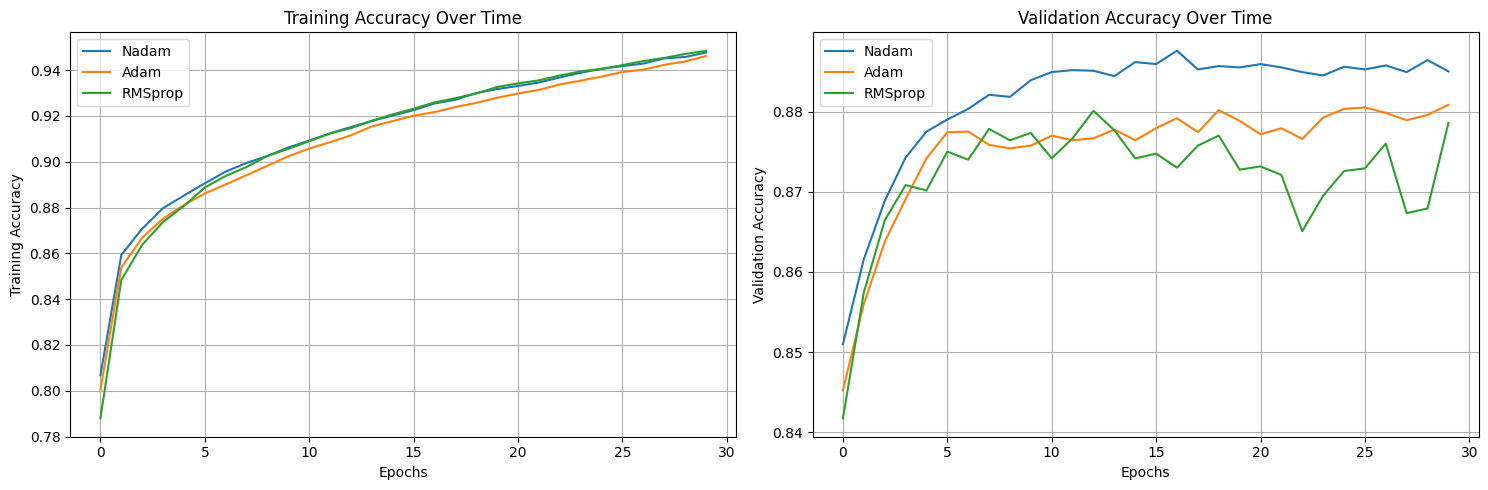

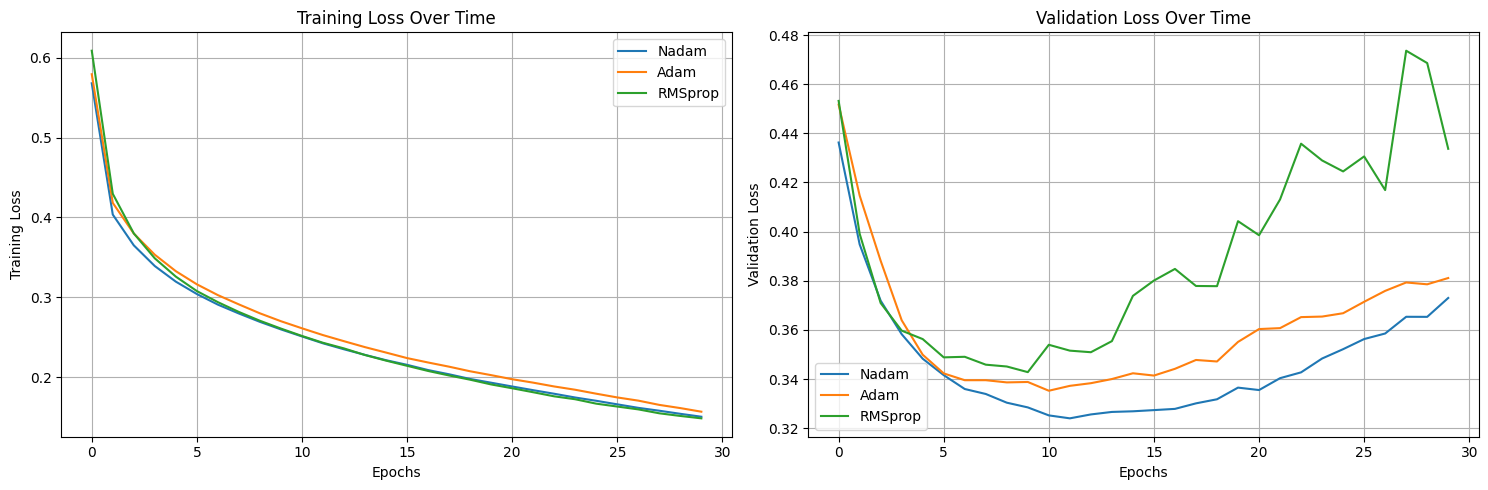

In [ ]:
plot(histories , "accuracy" , "val_accuracy" , "Training Accuracy" , "Validation Accuracy" , optimizers)
plot(histories , "loss" , "val_loss" , "Training Loss" , "Validation Loss" , optimizers)

## Optimizer Comparison & Overfitting Analysis  

### **Observations:**  
- **Training Accuracy:** All optimizers show similar improvement; **Nadam** slightly better.  
- **Validation Accuracy:** **Nadam** highest, **Adam** close, **RMSprop** unstable.  
- **Training Loss:** All decrease steadily, **Nadam & Adam** similar, **RMSprop** slightly higher.  
- **Validation Loss:** **Nadam** lowest (best generalization), **Adam** slightly higher, **RMSprop** fluctuates.  

### **Overfitting Signs:**  
- **RMSprop:** Most unstable, highest validation loss → **overfitting**.  
- **Adam:** Mild overfitting (validation loss increases slightly).  
- **Nadam:** Best generalization, lowest validation loss. starts overfitting eaither.

### **Best Choice:**  
- **Nadam** → Best validation accuracy & lowest validation loss.  



313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


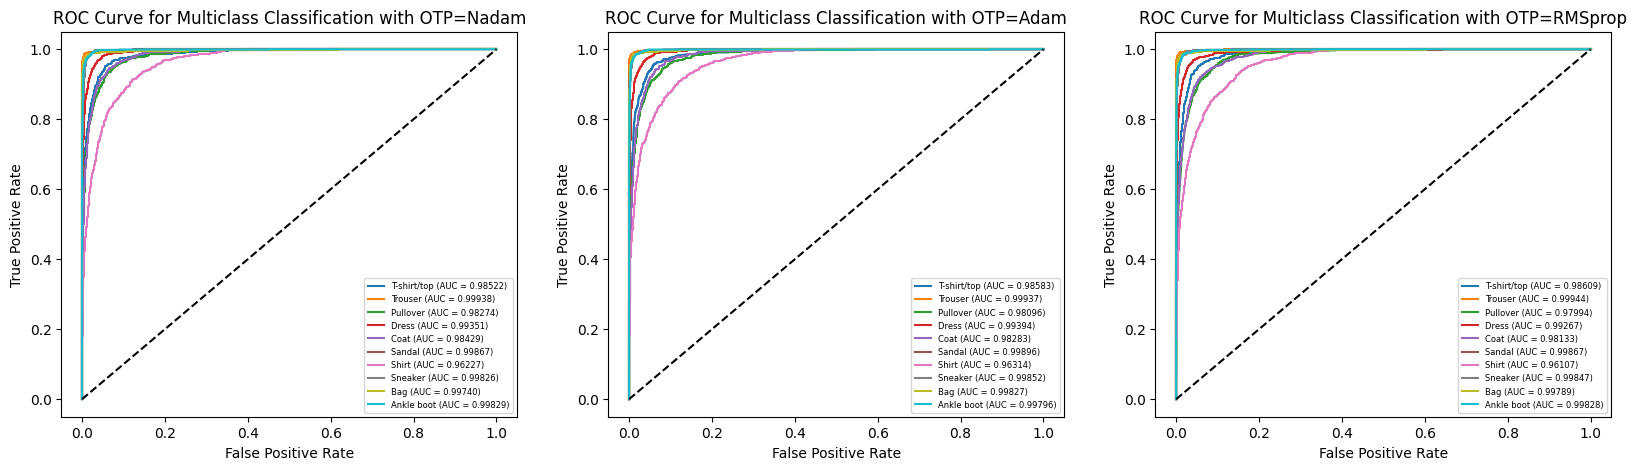

In [ ]:
# ROC curve for multiclass

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

def plot_roc_curve(models, x_test, y_test):
  # Binarize the output labels
  y_test_binarized = label_binarize(y_test, classes=np.arange(10))

  fig, axes = plt.subplots(1, 3, figsize=(20, 5))
  for j, model in enumerate(models):
    # Get predicted probabilities for each class
    y_pred_prob = model.predict(x_test)

    # Compute ROC curve and ROC area for each class
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    for i in range(10):
        fpr[i], tpr[i], _ = roc_curve(y_test_binarized[:, i], y_pred_prob[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Plot ROC curves for each class
    for i in range(10):
        axes[j].plot(fpr[i], tpr[i], label=f'{class_names[i]} (AUC = {roc_auc[i]:.5f})')

    axes[j].plot([0, 1], [0, 1], 'k--')  # Diagonal line
    axes[j].set_xlabel('False Positive Rate')
    axes[j].set_ylabel('True Positive Rate')
    axes[j].set_title('ROC Curve for Multiclass Classification with OTP='+ optimizers[j])
    axes[j].legend(loc='lower right', prop={'size': 6})
  plt.show()

plot_roc_curve(models , x_test , y_test)

## Q1.4

Here, we are going to consider 3 diffetrent hyperparametrs:
1. learning rate
2. number of nurouns in hidden layers
3. number of hidden layers


In [ ]:
# Define a function to train the model with different optimizers
from tensorflow.keras.layers import BatchNormalization

def train_with_optimizer(opt=tf.keras.optimizers.Nadam(), num_hidden_layers=1 , num_nurons=128 , verbose=1):
    model = keras.Sequential()
    model.add(InputLayer(shape=[28,28]))
    model.add(Flatten())
    for i in range(num_hidden_layers):
        model.add(Dense(num_nurons, activation='relu'))
        model.add(BatchNormalization())     # we add batch norm layer to increase stablity.
    model.add(Dense(10, activation='softmax'))

    model.compile(optimizer=opt,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    history = model.fit(x_train, y_train, epochs=30, batch_size=128, validation_split=0.2, verbose=verbose)
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
    return model , history, loss, accuracy

# Train the model with different optimizers
lr_list = [0.0001, 0.001 , 0.01]
num_hidden_layers_list = [1 , 2 , 3]
num_nurons_list = [64 , 128 , 256]


To have a better understanding how each hyperparameter is affecting the performance, we should check them one by one:

### Learning rate:


Based on previous steps, 'Nadam' optimizer seems to be better than Adam and RMSProp. So we are going to use this optimzer in all our tests. In the first test, we change the learning rate of this optimizer:

In [ ]:
histories_lr = []
models_lr = []
losses_lr = []
accuracies_lr = []

for lr in lr_list:
    print("**************  " + str(lr) + "  **************")
    opt = tf.keras.optimizers.Nadam(learning_rate=lr)
    model, history, loss, accuracy = train_with_optimizer(opt, 2, 128)      # the model with 2 hidden layers is more complex, leading to better results.
    models_lr.append(model)
    histories_lr.append(history)
    losses_lr.append(loss)
    accuracies_lr.append(accuracy)
    print(f"Learning Rate: {lr}, Loss: {loss:.4f}, Accuracy: {accuracy:.4f}")



**************  0.0001  **************
Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.6109 - loss: 1.1705 - val_accuracy: 0.8153 - val_loss: 0.5572
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8309 - loss: 0.4880 - val_accuracy: 0.8483 - val_loss: 0.4358
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8552 - loss: 0.4152 - val_accuracy: 0.8595 - val_loss: 0.3994
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8676 - loss: 0.3767 - val_accuracy: 0.8649 - val_loss: 0.3792
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8766 - loss: 0.3510 - val_accuracy: 0.8699 - val_loss: 0.3672
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8849 - loss: 0.3311 - val_accuracy: 0.8707 - val_loss: 0.3578
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8904 - loss: 0.3141 - val_accuracy: 0.8733 - val_loss: 0.3506
Epoch 8/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0

Now, let's visulize the results:

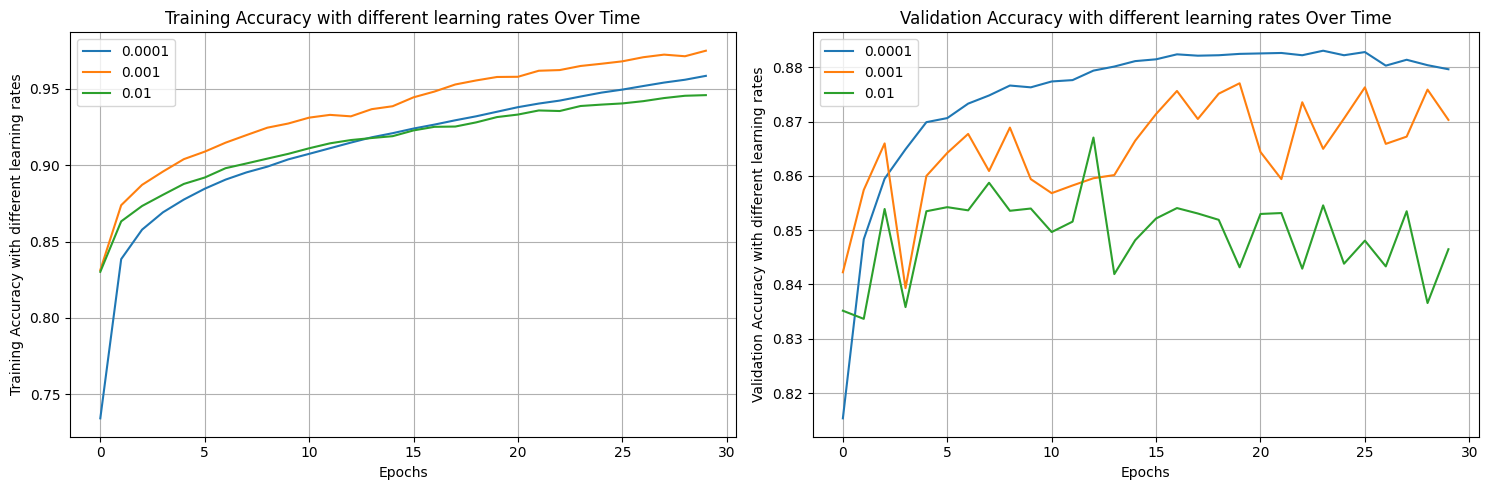

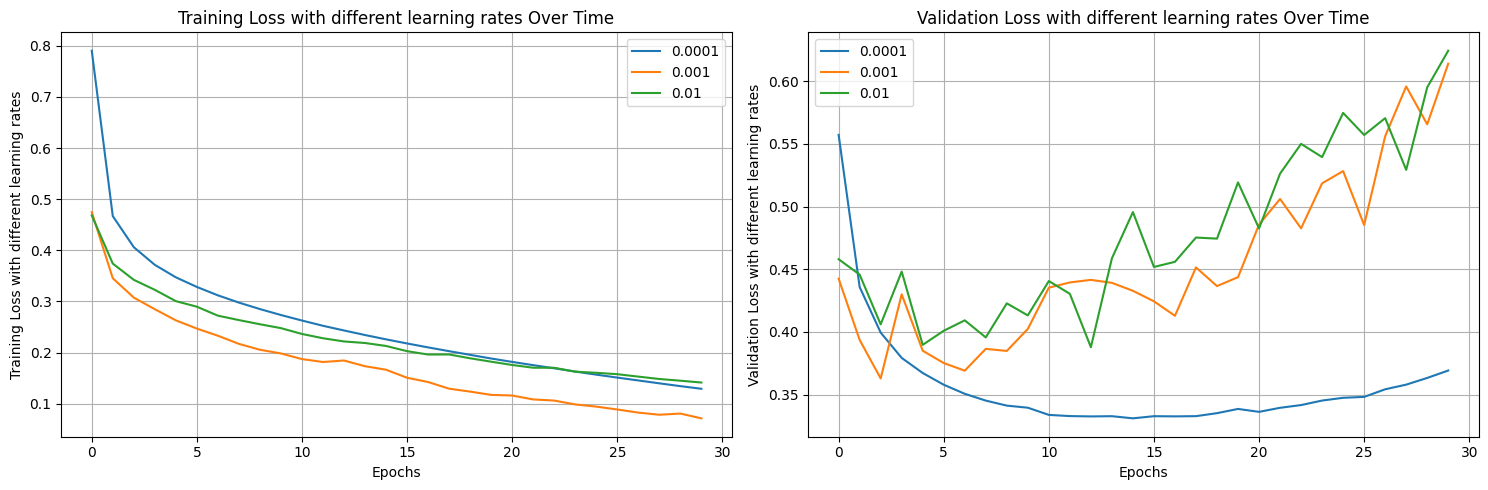

In [ ]:
plot(histories_lr , "accuracy" , "val_accuracy" , "Training Accuracy with different learning rates" , "Validation Accuracy with different learning rates" , lr_list)
plot(histories_lr , "loss" , "val_loss" , "Training Loss with different learning rates" , "Validation Loss with different learning rates", lr_list)

## Learning Rate Comparison Analysis  

### **Key Insights:**  
- **0.0001** provides the best **generalization**, with stable validation accuracy and the lowest validation loss.  
- **0.001** achieves the highest **training accuracy**, but its validation loss increases, indicating **overfitting**.  
- **0.01** is unstable, with fluctuating validation accuracy and increasing validation loss, leading to **poor generalization**.  

### **Overfitting & Stability:**  
- **0.0001:** Most stable, minimal overfitting.  
- **0.001:** Overfits—high training accuracy but worsening validation loss.  
- **0.01:** Unstable, validation performance deteriorates.  

### **Best Learning Rate Choice:**  
- **0.0001** → Best for balanced training and validation performance. not fluctuating and also less overfitting than the other two!


Let's plot confustion matrix for each option to have a better look at the performance.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


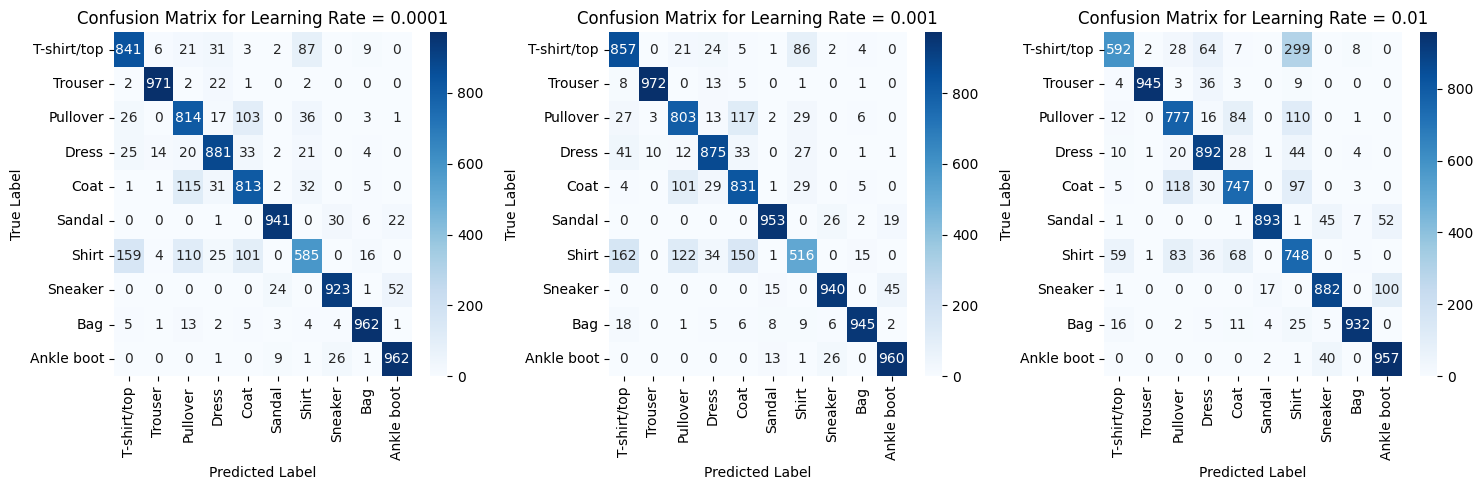

In [ ]:
def plot_confusion_matrices(models, x_test, y_test, class_names):
  fig, axes = plt.subplots(1, 3, figsize=(15, 5))
  for i, model in enumerate(models):
      y_pred = np.argmax(model.predict(x_test), axis=1)
      cm = confusion_matrix(y_test, y_pred)
      sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[i],
                  xticklabels=class_names, yticklabels=class_names)
      axes[i].set_xlabel("Predicted Label")
      axes[i].set_ylabel("True Label")
      axes[i].set_title(f"Confusion Matrix for Learning Rate = {lr_list[i]}")
  plt.tight_layout()
  plt.show()

plot_confusion_matrices(models_lr, x_test, y_test, class_names)


In [ ]:
from sklearn.metrics import classification_report

def report(models, x_test, y_test, class_names):
    for i, model in enumerate(models):
      y_pred = np.argmax(model.predict(x_test), axis=1)
      print(f"Classification Report for Learning Rate = {lr_list[i]}")
      print(classification_report(y_test, y_pred, target_names=class_names))

report(models_lr, x_test, y_test, class_names)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Classification Report for Learning Rate = 0.0001
              precision    recall  f1-score   support

 T-shirt/top       0.79      0.84      0.82      1000
     Trouser       0.97      0.97      0.97      1000
    Pullover       0.74      0.81      0.78      1000
       Dress       0.87      0.88      0.88      1000
        Coat       0.77      0.81      0.79      1000
      Sandal       0.96      0.94      0.95      1000
       Shirt       0.76      0.58      0.66      1000
     Sneaker       0.94      0.92      0.93      1000
         Bag       0.96      0.96      0.96      1000
  Ankle boot       0.93      0.96      0.94      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Classification Report for Learning Rate = 0.001
              precision    recall  f1-score   support

 T-shir

And let's see how they affect the most-confused class :

In [ ]:
differ = []
for i, model in enumerate(models_lr):
    print(f"Analyzing model with learning rate: {lr_list[i]}")
    y_pred = np.argmax(model.predict(x_test), axis=1)
    cm = confusion_matrix(y_test, y_pred)
    x = most_confused_classes(cm, class_names)
    differ.append(x)
    print("-" * 20)

Analyzing model with learning rate: 0.0001
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Most confused classes:
T-shirt/top: Shirt
Trouser: Dress
Pullover: Coat
Dress: Coat
Coat: Pullover
Sandal: Sneaker
Shirt: T-shirt/top
Sneaker: Ankle boot
Bag: Pullover
Ankle boot: Sneaker
--------------------
Analyzing model with learning rate: 0.001
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Most confused classes:
T-shirt/top: Shirt
Trouser: Dress
Pullover: Coat
Dress: T-shirt/top
Coat: Pullover
Sandal: Sneaker
Shirt: T-shirt/top
Sneaker: Ankle boot
Bag: T-shirt/top
Ankle boot: Sneaker
--------------------
Analyzing model with learning rate: 0.01
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Most confused classes:
T-shirt/top: Shirt
Trouser: Dress
Pullover: Shirt
Dress: Shirt
Coat: Pullover
Sandal: Ankle boot
Shirt: Pullover
Sneaker: Ankle boot
Bag: Shirt
Ankle boot: Sneaker
--------------------


In [ ]:
df = pd.DataFrame(differ)
df

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
0,Shirt,Dress,Coat,Coat,Pullover,Sneaker,T-shirt/top,Ankle boot,Pullover,Sneaker
1,Shirt,Dress,Coat,T-shirt/top,Pullover,Sneaker,T-shirt/top,Ankle boot,T-shirt/top,Sneaker
2,Shirt,Dress,Shirt,Shirt,Pullover,Ankle boot,Pullover,Ankle boot,Shirt,Sneaker


There are some differences between three models for most confused class. But in conclusion, lower learning rate results in more accurate results.

### Effect of number of nurons in each hidden layer:

In [ ]:
# ### Number of neurons in hidden layers:
histories_neuron = []
models_neuron = []
losses_neuron = []
accuracies_neuron = []

for neuron in num_nurons_list:
    opt = tf.keras.optimizers.Nadam(learning_rate=0.0001)     # we choose the best lr from previous step.
    model, history, loss, accuracy = train_with_optimizer(opt, 2, neuron)
    models_neuron.append(model)
    histories_neuron.append(history)
    losses_neuron.append(loss)
    accuracies_neuron.append(accuracy)
    print(f"Number of neurons: {neuron}, Loss: {loss:.4f}, Accuracy: {accuracy:.4f}")

Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5259 - loss: 1.5094 - val_accuracy: 0.7916 - val_loss: 0.6734
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8056 - loss: 0.6027 - val_accuracy: 0.8233 - val_loss: 0.5174
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8330 - loss: 0.4957 - val_accuracy: 0.8372 - val_loss: 0.4681
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8479 - loss: 0.4450 - val_accuracy: 0.8469 - val_loss: 0.4347
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8574 - loss: 0.4136 - val_accuracy: 0.8530 - val_loss: 0.4142
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8647 - loss: 0.3909 - val_accuracy: 0.8575 - val_loss: 0.3998
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8703 - loss: 0.3730 - val_accuracy: 0.8622 - val_loss: 0.3888
Epoch 8/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8757 - loss: 0.3581 - val_accuracy: 0.

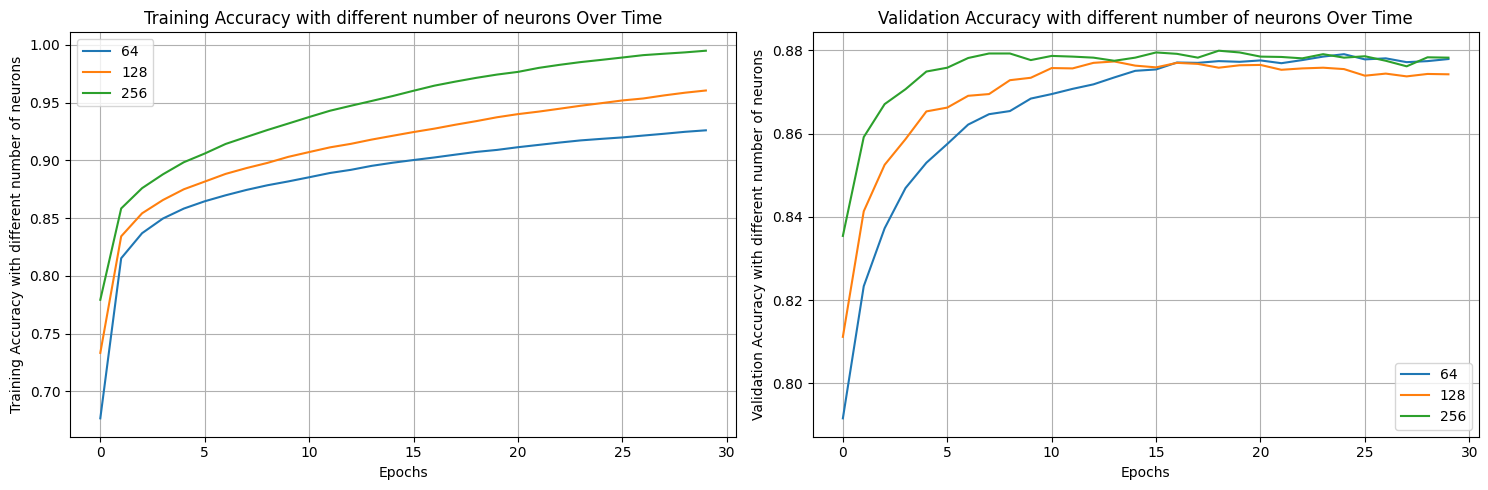

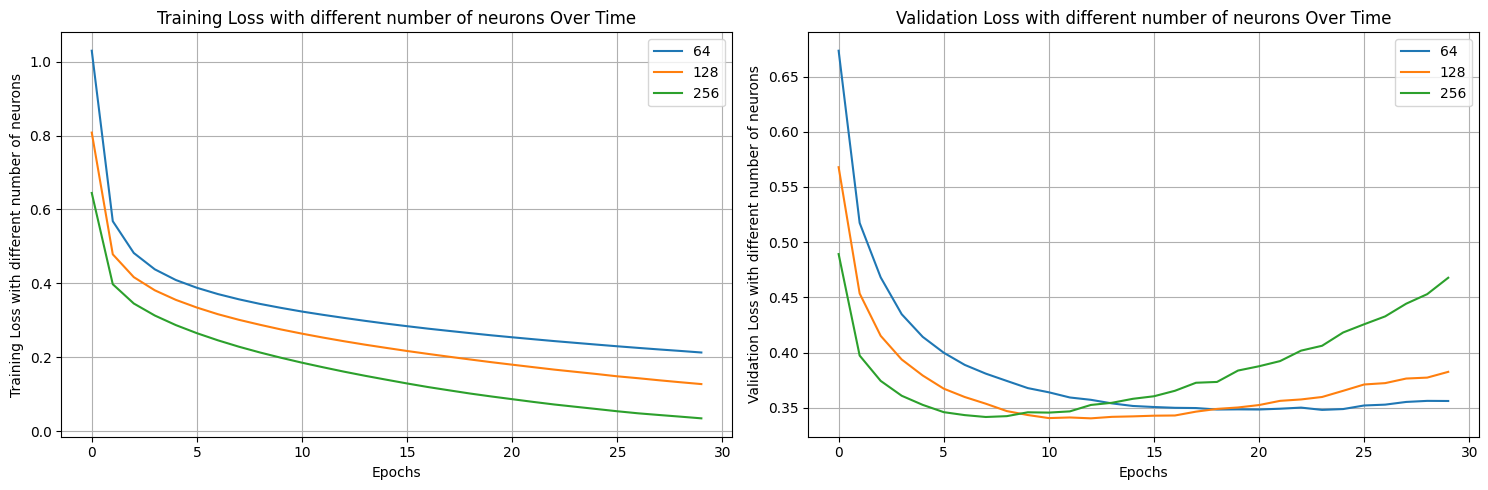

In [ ]:
plot(histories_neuron , "accuracy" , "val_accuracy" , "Training Accuracy with different number of neurons" , "Validation Accuracy with different number of neurons", num_nurons_list)
plot(histories_neuron , "loss" , "val_loss" , "Training Loss with different number of neurons" , "Validation Loss with different number of neurons" , num_nurons_list)


## Neuron Count Comparison Analysis  

### **Observations:**  
- **Higher neurons (256) → Faster training, better training accuracy, lower training loss.**  
- **Validation performance peaks at 128 neurons** → Highest validation accuracy, lowest validation loss.  
- **256 neurons start overfitting** → Validation loss increases after ~20 epochs, diverging from training loss.  

### **Overfitting & Generalization:**  
- **64 neurons** → Underfits, slower convergence, lower accuracy.  
- **128 neurons** → Best balance, strong validation accuracy, minimal overfitting.  
- **256 neurons** → Overfits, poor generalization despite excellent training performance.  

### **Best Choice:**  
Altough 64 is seems to be the best according to validation tests, but its performance is lower than the other two in training.
- **128 neurons** → Optimal balance between performance and overfitting.  


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


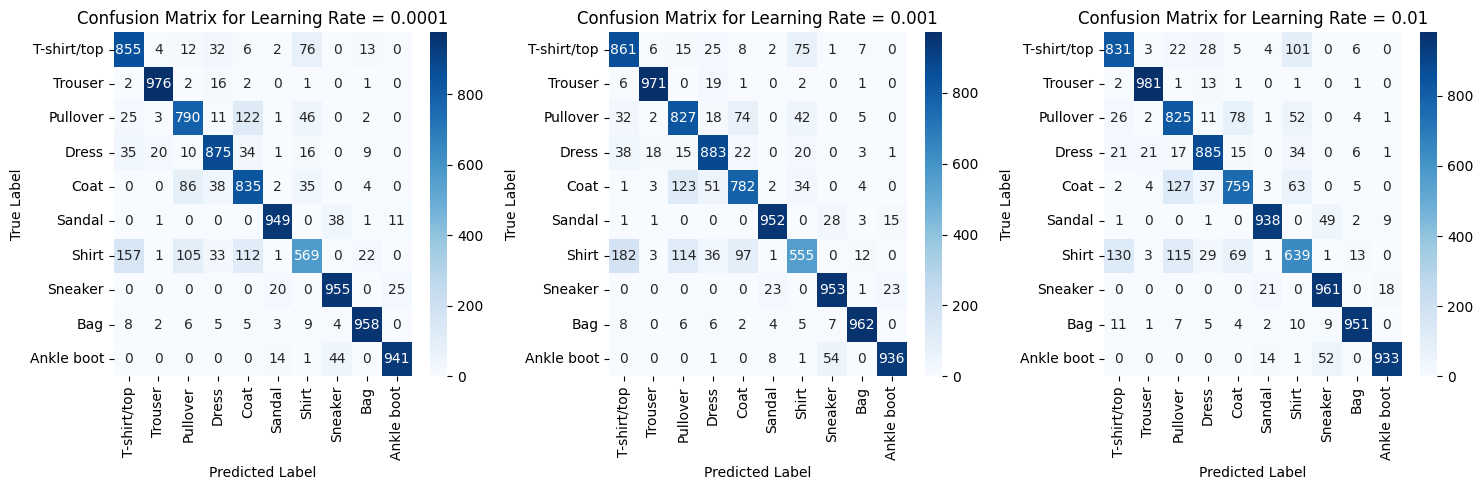

In [ ]:
plot_confusion_matrices(models_neuron, x_test, y_test, class_names)

In [ ]:
report(models_neuron, x_test, y_test, class_names)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Classification Report for Learning Rate = 0.0001
              precision    recall  f1-score   support

 T-shirt/top       0.79      0.85      0.82      1000
     Trouser       0.97      0.98      0.97      1000
    Pullover       0.78      0.79      0.79      1000
       Dress       0.87      0.88      0.87      1000
        Coat       0.75      0.83      0.79      1000
      Sandal       0.96      0.95      0.95      1000
       Shirt       0.76      0.57      0.65      1000
     Sneaker       0.92      0.95      0.94      1000
         Bag       0.95      0.96      0.95      1000
  Ankle boot       0.96      0.94      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Classification Report for Learning Rate = 0.001
              precision    recall  f1-score   support

 T-shir

In [ ]:
differ = []
for i, model in enumerate(models_neuron):
    print(f"Analyzing model with nuron size: {num_nurons_list[i]}")
    y_pred = np.argmax(model.predict(x_test), axis=1)
    cm = confusion_matrix(y_test, y_pred)
    x = most_confused_classes(cm, class_names)
    differ.append(x)
    print("-" * 20)

Analyzing model with nuron size: 64
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Most confused classes:
T-shirt/top: Shirt
Trouser: Dress
Pullover: Coat
Dress: T-shirt/top
Coat: Pullover
Sandal: Sneaker
Shirt: T-shirt/top
Sneaker: Ankle boot
Bag: Shirt
Ankle boot: Sneaker
--------------------
Analyzing model with nuron size: 128
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Most confused classes:
T-shirt/top: Shirt
Trouser: Dress
Pullover: Coat
Dress: T-shirt/top
Coat: Pullover
Sandal: Sneaker
Shirt: T-shirt/top
Sneaker: Sandal
Bag: T-shirt/top
Ankle boot: Sneaker
--------------------
Analyzing model with nuron size: 256
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Most confused classes:
T-shirt/top: Shirt
Trouser: Dress
Pullover: Coat
Dress: Shirt
Coat: Pullover
Sandal: Sneaker
Shirt: T-shirt/top
Sneaker: Sandal
Bag: T-shirt/top
Ankle boot: Sneaker
--------------------


In [ ]:
df = pd.DataFrame(differ)
df

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
0,Shirt,Dress,Coat,T-shirt/top,Pullover,Sneaker,T-shirt/top,Ankle boot,Shirt,Sneaker
1,Shirt,Dress,Coat,T-shirt/top,Pullover,Sneaker,T-shirt/top,Sandal,T-shirt/top,Sneaker
2,Shirt,Dress,Coat,Shirt,Pullover,Sneaker,T-shirt/top,Sandal,T-shirt/top,Sneaker


### Effect of numbe of hidden layers.

In [ ]:
### Number of hidden layers:
histories_hidden = []
models_hidden = []
losses_hidden = []
accuracies_hidden = []

for hidden_layer in num_hidden_layers_list:
    opt = tf.keras.optimizers.Nadam(learning_rate=0.0001)
    model, history, loss, accuracy = train_with_optimizer(opt, hidden_layer, 256)
    models_hidden.append(model)
    histories_hidden.append(history)
    losses_hidden.append(loss)
    accuracies_hidden.append(accuracy)
    print(f"Number of hidden layers: {hidden_layer}, Loss: {loss:.4f}, Accuracy: {accuracy:.4f}")


Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6367 - loss: 1.0771 - val_accuracy: 0.8238 - val_loss: 0.5443
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8401 - loss: 0.4653 - val_accuracy: 0.8494 - val_loss: 0.4305
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8595 - loss: 0.4027 - val_accuracy: 0.8592 - val_loss: 0.4007
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8708 - loss: 0.3682 - val_accuracy: 0.8668 - val_loss: 0.3816
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8791 - loss: 0.3433 - val_accuracy: 0.8706 - val_loss: 0.3692
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8864 - loss: 0.3228 - val_accuracy: 0.8735 - val_loss: 0.3599
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8932 - loss: 0.3052 - val_accuracy: 0.8763 - val_loss: 0.3521
Epoch 8/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8992 - loss: 0.2897 - val_accuracy: 0.

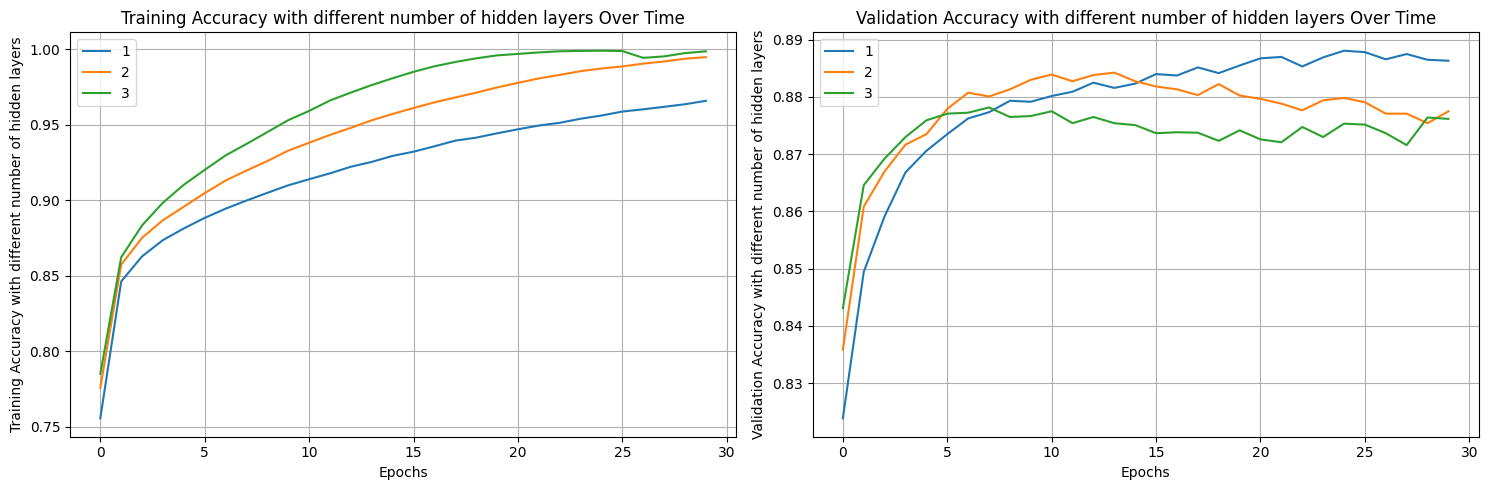

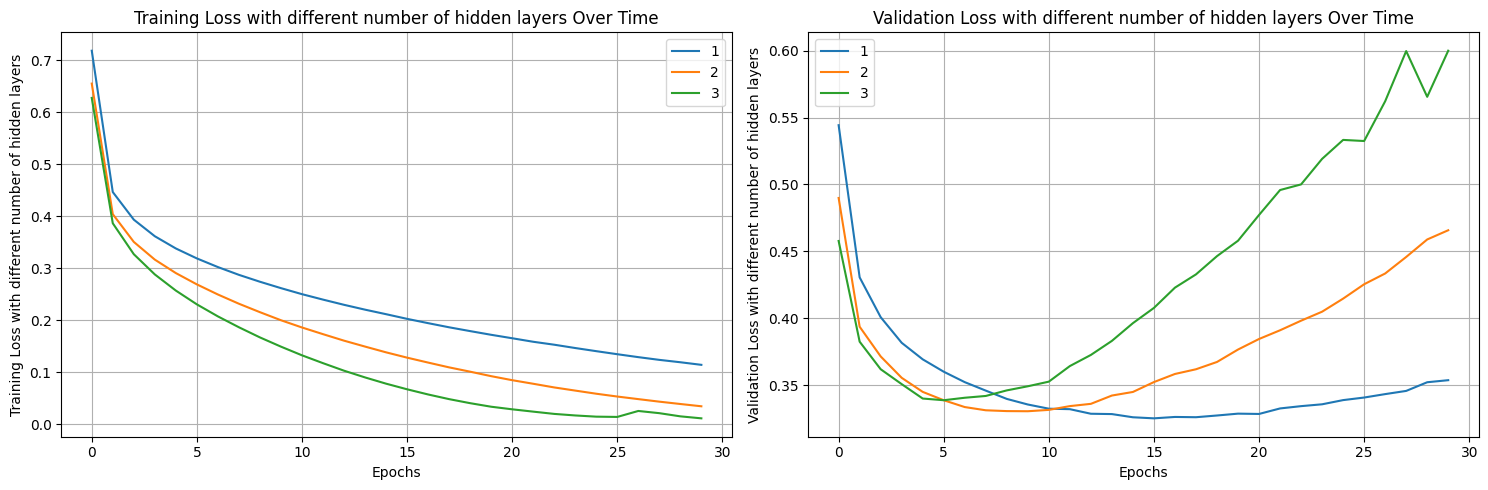

In [ ]:
plot(histories_hidden , "accuracy" , "val_accuracy" , "Training Accuracy with different number of hidden layers" , "Validation Accuracy with different number of hidden layers" , num_hidden_layers_list)
plot(histories_hidden , "loss" , "val_loss" , "Training Loss with different number of hidden layers" , "Validation Loss with different number of hidden layers", num_hidden_layers_list)

Persoannly, I will choose 1 hidden layer as it shows less overfitting than the other two, thus generalize better!

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


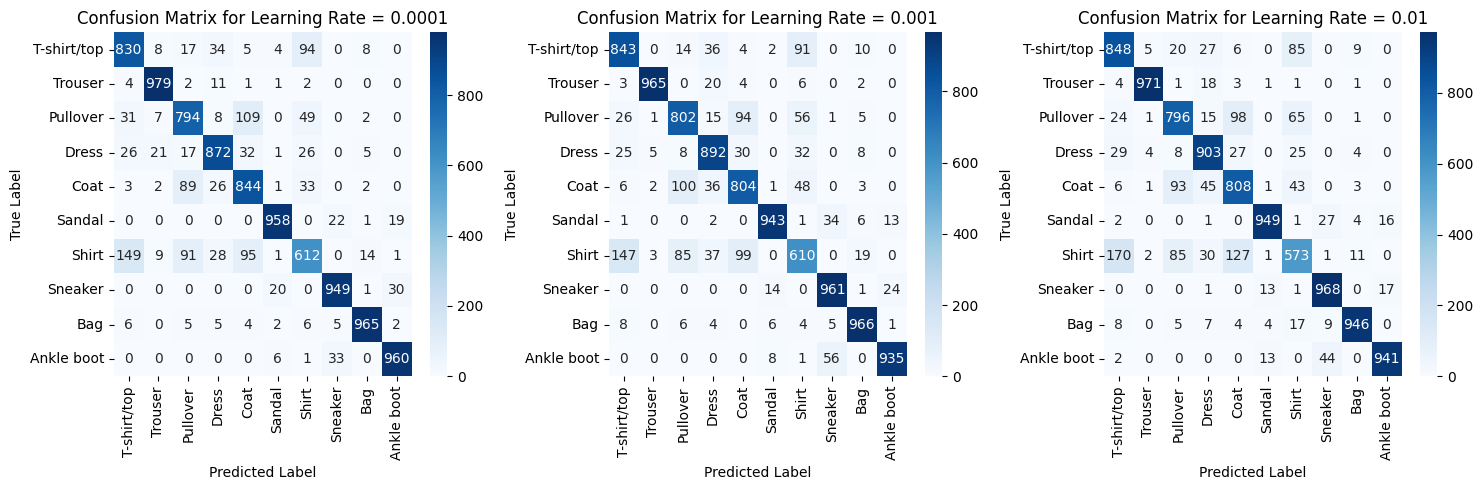

In [ ]:
plot_confusion_matrices(models_hidden, x_test, y_test, class_names)

In [ ]:
report(models_hidden, x_test, y_test, class_names)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Classification Report for Learning Rate = 0.0001
              precision    recall  f1-score   support

 T-shirt/top       0.79      0.83      0.81      1000
     Trouser       0.95      0.98      0.97      1000
    Pullover       0.78      0.79      0.79      1000
       Dress       0.89      0.87      0.88      1000
        Coat       0.77      0.84      0.81      1000
      Sandal       0.96      0.96      0.96      1000
       Shirt       0.74      0.61      0.67      1000
     Sneaker       0.94      0.95      0.94      1000
         Bag       0.97      0.96      0.97      1000
  Ankle boot       0.95      0.96      0.95      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.87     10000
weighted avg       0.88      0.88      0.87     10000

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Classification Report for Learning Rate = 0.001
              precision    recall  f1-score   support

 T-shir

In [ ]:
differ = []
for i, model in enumerate(models_hidden):
    print(f"Analyzing model with layer depth: {num_hidden_layers_list[i]}")
    y_pred = np.argmax(model.predict(x_test), axis=1)
    cm = confusion_matrix(y_test, y_pred)
    x = most_confused_classes(cm, class_names)
    differ.append(x)
    print("-" * 20)

Analyzing model with layer depth: 1
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Most confused classes:
T-shirt/top: Shirt
Trouser: Dress
Pullover: Coat
Dress: Coat
Coat: Pullover
Sandal: Sneaker
Shirt: T-shirt/top
Sneaker: Ankle boot
Bag: T-shirt/top
Ankle boot: Sneaker
--------------------
Analyzing model with layer depth: 2
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Most confused classes:
T-shirt/top: Shirt
Trouser: Dress
Pullover: Coat
Dress: Shirt
Coat: Pullover
Sandal: Sneaker
Shirt: T-shirt/top
Sneaker: Ankle boot
Bag: T-shirt/top
Ankle boot: Sneaker
--------------------
Analyzing model with layer depth: 3
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Most confused classes:
T-shirt/top: Shirt
Trouser: Dress
Pullover: Coat
Dress: T-shirt/top
Coat: Pullover
Sandal: Sneaker
Shirt: T-shirt/top
Sneaker: Ankle boot
Bag: Shirt
Ankle boot: Sneaker
--------------------


In [ ]:
df = pd.DataFrame(differ)
df

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
0,Shirt,Dress,Coat,Coat,Pullover,Sneaker,T-shirt/top,Ankle boot,T-shirt/top,Sneaker
1,Shirt,Dress,Coat,Shirt,Pullover,Sneaker,T-shirt/top,Ankle boot,T-shirt/top,Sneaker
2,Shirt,Dress,Coat,T-shirt/top,Pullover,Sneaker,T-shirt/top,Ankle boot,Shirt,Sneaker


### ALL TOGETHER!

Now, if we consider all of them togetherT which combination outperforms the others? let's see:

In [ ]:

import itertools

# Create all combinations of hyperparameters
param_combinations = list(itertools.product(lr_list, num_hidden_layers_list, num_nurons_list))

histories_combinations = []
models_combinations = []
losses_combinations = []
accuracies_combinations = []

for combination in param_combinations:
    lr, num_hidden_layers, num_neurons = combination
    print(f"Training with combination: lr={lr}, hidden_layers={num_hidden_layers}, neurons={num_neurons}")
    opt = tf.keras.optimizers.Nadam(learning_rate=lr)
    model, history, loss, accuracy = train_with_optimizer(opt, num_hidden_layers, num_neurons , verbose=0)
    models_combinations.append(model)
    histories_combinations.append(history)
    losses_combinations.append(loss)
    accuracies_combinations.append(accuracy)
    print(f"Combination: {combination}, Loss: {loss:.6f}, Accuracy: {accuracy:.6f}")

# You can further analyze these results (e.g., find the best combination)
best_combination_index = np.argmax(accuracies_combinations)
best_combination = param_combinations[best_combination_index]
print(f"Best combination: {best_combination}, Accuracy: {accuracies_combinations[best_combination_index]:.4f}")


Training with combination: lr=0.0001, hidden_layers=1, neurons=64
Combination: (0.0001, 1, 64), Loss: 0.377349, Accuracy: 0.869500
Training with combination: lr=0.0001, hidden_layers=1, neurons=128
Combination: (0.0001, 1, 128), Loss: 0.374687, Accuracy: 0.874000
Training with combination: lr=0.0001, hidden_layers=1, neurons=256
Combination: (0.0001, 1, 256), Loss: 0.380575, Accuracy: 0.878700
Training with combination: lr=0.0001, hidden_layers=2, neurons=64
Combination: (0.0001, 2, 64), Loss: 0.384271, Accuracy: 0.870900
Training with combination: lr=0.0001, hidden_layers=2, neurons=128
Combination: (0.0001, 2, 128), Loss: 0.408292, Accuracy: 0.870800
Training with combination: lr=0.0001, hidden_layers=2, neurons=256
Combination: (0.0001, 2, 256), Loss: 0.534666, Accuracy: 0.867800
Training with combination: lr=0.0001, hidden_layers=3, neurons=64
Combination: (0.0001, 3, 64), Loss: 0.402038, Accuracy: 0.866200
Training with combination: lr=0.0001, hidden_layers=3, neurons=128
Combinat

This result is not compatible with our sole finding where 256 nurons per hidden layer was the worst. Here, in combination with number of hidden layers and lower learning rates, it seems 256 performs better.

# Question 2

## Part 2.1

### Part A

In [ ]:
from sklearn.datasets import load_wine
import pandas as pd

wine = load_wine()
df = pd.DataFrame(data=wine.data, columns=wine.feature_names)
df['target'] = wine.target
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [ ]:
wine.target_names

array(['class_0', 'class_1', 'class_2'], dtype='<U7')

This code cell loads the wine dataset from scikit-learn and creates a Pandas DataFrame. Let's break down each part:

1. **Import necessary libraries:**
   - `from sklearn.datasets import load_wine`: Imports the `load_wine` function from scikit-learn, which allows us to access the wine dataset.
   - `import pandas as pd`: Imports the pandas library and assigns it the alias `pd`, which is commonly used for data manipulation and analysis.

2. **Load the wine dataset:**
   - `wine = load_wine()`: Loads the wine dataset into the `wine` variable.  This object contains various attributes like the data itself (features), target variables (class labels), and feature names.

3. **Create a Pandas DataFrame:**
   - `df = pd.DataFrame(data=wine.data, columns=wine.feature_names)`: This line creates a pandas DataFrame (`df`) from the wine dataset.
     - `data=wine.data`: Specifies that the data for the DataFrame should come from the `data` attribute of the `wine` object.  This attribute is a NumPy array containing the numerical features of each wine sample.
     - `columns=wine.feature_names`: Sets the column names of the DataFrame using the `feature_names` attribute of the `wine` object. These are the names of the different chemical properties (e.g., alcohol content, malic acid, etc.) measured for each wine sample.

4. **Display the first few rows:**
   - `df.head()`: Displays the first five rows of the DataFrame. This gives a quick overview of the data and the column names.


In summary, this code loads a well-known dataset (wine), transforms it into a tabular format using pandas (which is well-suited for data analysis), and provides a preview of the data. This sets up the data for further exploration and analysis in subsequent code cells.

Now for showing the distribution of these two columns first we want to plot the histogram of them.

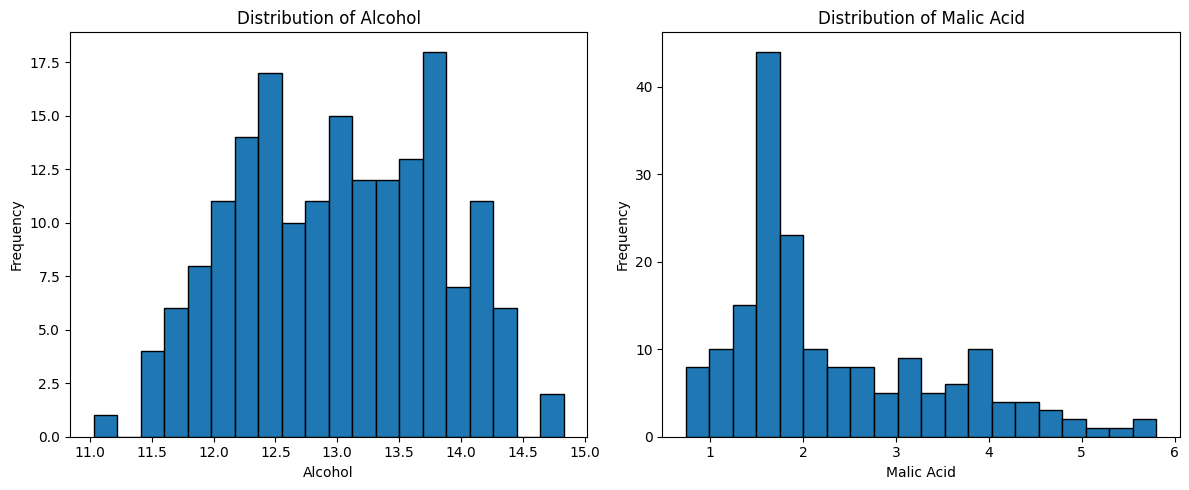

In [ ]:
import matplotlib.pyplot as plt

# Assuming 'alcohol' and 'malic_acid' are in your DataFrame
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df['alcohol'], bins=20, edgecolor='black')
plt.title('Distribution of Alcohol')
plt.xlabel('Alcohol')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(df['malic_acid'], bins=20, edgecolor='black')
plt.title('Distribution of Malic Acid')
plt.xlabel('Malic Acid')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


**Distribution of Alcohol and Malic Acid in Wine Dataset**

This plot displays the distributions of alcohol and malic acid content in the wine dataset.  Two histograms are presented side-by-side:

**Left Histogram: Alcohol Content**

* Shows the frequency distribution of alcohol levels across the wine samples.
* The x-axis represents the alcohol content.
* The y-axis represents the number of wine samples with that alcohol content (frequency).

**Right Histogram: Malic Acid Content**

* Shows the frequency distribution of malic acid levels across the wine samples.
* The x-axis represents the malic acid content.
* The y-axis represents the number of wine samples with that malic acid content (frequency).

**Observations:**

The alcohol content appears to be somewhat normally distributed, while the malic acid content seems to be skewed towards the lower values. we should pay attention to this behavior

Now we plot the joint plot of their distribution for having another type of intuition behind their behavior:

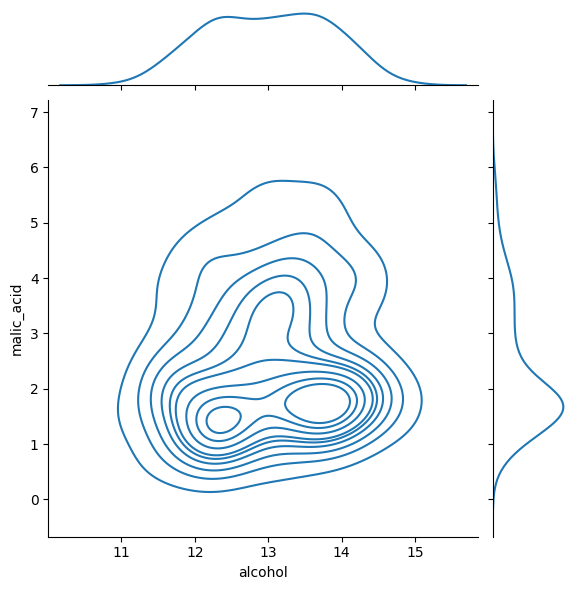

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.jointplot(data=df, x='alcohol', y='malic_acid', kind='kde')
plt.show()


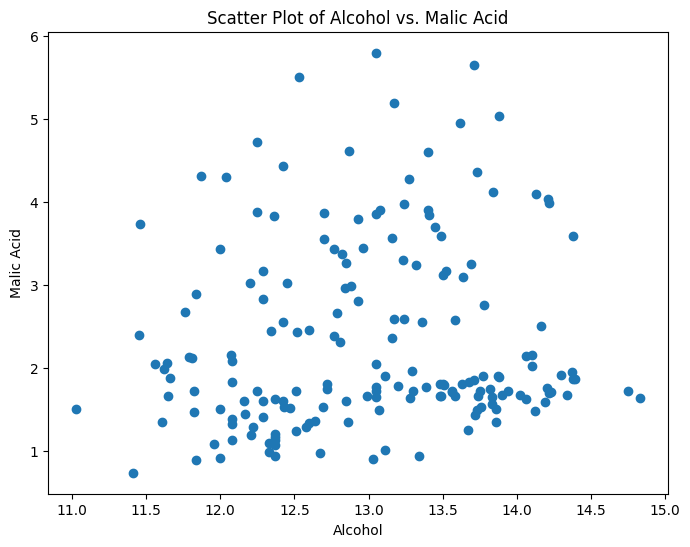

In [ ]:
#Use Scatter plot for showing these things in 2 dimensions
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.scatter(df['alcohol'], df['malic_acid'])
plt.xlabel('Alcohol')
plt.ylabel('Malic Acid')
plt.title('Scatter Plot of Alcohol vs. Malic Acid')
plt.show()


The same thing is shown in these two plots like the first one.The alcohol content appears to be somewhat normally distributed, while the malic acid content seems to be skewed towards the lower values. we should pay attention to this behavior

First we define a class repressenting AdalineGD:

In [ ]:
class AdalineGD:
    def __init__(self, eta=0.01, n_iter=50, random_state=42):
        self.eta = eta
        self.n_iter = n_iter
        self.random_state = random_state

    def fit(self, X, y):
        rgen = np.random.RandomState(self.random_state)
        self.w_ = rgen.normal(loc=0.0, scale=0.01, size=1 + X.shape[1])
        self.cost_ = []

        for i in range(self.n_iter):
            net_input = self.net_input(X)
            output = self.activation(net_input)
            errors = (y - output)
            self.w_[1:] += self.eta * X.T.dot(errors)
            self.w_[0] += self.eta * errors.sum()
            cost = (errors**2).sum() / 2.0
            self.cost_.append(cost)
        return self

    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def activation(self, X):
        return X

    def predict(self, X):
        return np.where(self.activation(self.net_input(X)) >= 0.0, 1, 0)

Now we write a function which takes a class number to detect from others as input, and then train an Adaline model with hyperparameter tuning

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

def train_and_evaluate_adaline(class_number, df):
    # Prepare the data
    X = df.drop('target', axis=1).values
    y = df['target'].apply(lambda x: 1 if x == class_number else 0).values  # Detect class number from others

    # Split data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Feature scaling
    sc = StandardScaler()
    X_train_std = sc.fit_transform(X_train)
    X_test_std = sc.transform(X_test)

    # Split training data into training and validation
    X_train_split, X_val, y_train_split, y_val = train_test_split(X_train_std, y_train, test_size=0.1, random_state=42)

    NUMBER_OF_ITTERATIONS = [20, 50, 100, 200, 400, 500]
    LEARNING_RATES = [0.00001, 0.0001, 0.001]

    best_accuracy = float('inf')
    best_eta = None
    best_n_iter = None

    for n_iter in NUMBER_OF_ITTERATIONS:
        for eta in LEARNING_RATES:
            ada = AdalineGD(n_iter=n_iter, eta=eta)
            ada.fit(X_train_split, y_train_split)

            # Make predictions on validation set
            y_val_pred = ada.predict(X_val)

            # Calculate accuracy on validation set
            accuracy = np.mean(y_val_pred == y_val)

            if accuracy < best_accuracy:
                best_accuracy = accuracy
                best_eta = eta
                best_n_iter = n_iter

    # Train the Adaline model with best hyperparameters
    ada = AdalineGD(n_iter=best_n_iter, eta=best_eta)
    ada.fit(X_train_std, y_train)

    # Make predictions on test set
    y_pred = ada.predict(X_test_std)

    # Calculate accuracy on test set
    accuracy = np.mean(y_pred == y_test)

    return accuracy, ada


Use the function above for dettecting the class 0 from others

In [ ]:
accuracy_class0, ada_class0 = train_and_evaluate_adaline(0, df)
print(f"Accuracy for class 0: {accuracy_class0}")

Accuracy for class 0: 0.5555555555555556


Visualize the cost plot based on the best ada model

In [ ]:

import plotly.graph_objects as go

# Visualize the cost history
fig = go.Figure()
fig.add_trace(go.Scatter(y=ada_class0.cost_, mode='lines', name='Cost'))
fig.update_layout(title='Cost of AdalineGD Model', xaxis_title='Epoch', yaxis_title='Cost')
fig.show()


### Part B

Now we do the sam task for detecting class 1 from others (means 0 and 2)

In [ ]:
accuracy_class1, ada_class1 = train_and_evaluate_adaline(1, df)
print(f"Accuracy for class 1: {accuracy_class1}")

Accuracy for class 1: 0.6944444444444444


Now visualize the cost function:

In [ ]:
# Visualize the cost

fig = go.Figure()
fig.add_trace(go.Scatter(y=ada_class1.cost_, mode='lines', name='Cost'))
fig.update_layout(title='Cost of AdalineGD Model', xaxis_title='Epoch', yaxis_title='Cost')
fig.show()

### Possible Reasons for Discrepancy in Class Detection Accuracy

**Potential Factors Affecting Class 0 Detection:**

* **Class Distribution Imbalance:**  If class 0 is significantly underrepresented compared to other classes (classes 1 and 2) in the dataset, the model might be biased towards the majority classes. This could lead to lower accuracy in correctly identifying the minority class (class 0).
* **Feature Importance:**  Certain features might be more discriminative for separating class 0 from others, while other features may be less informative or even misleading. The model's reliance on less informative features could contribute to lower accuracy.  The visualizations (histograms and scatter plots) of 'alcohol' and 'malic_acid' give a starting point for exploring the relationships between these features and the classes.  Further analysis of feature distributions for class 0 would be beneficial.
* **Feature Overlap:**  If the feature distributions of class 0 significantly overlap with those of other classes, it might be inherently more difficult for the linear model (AdalineGD) to draw a clear boundary between them.
* **Hyperparameter Sensitivity:** The chosen hyperparameters (learning rate and number of iterations) may be suboptimal for class 0 detection. While hyperparameter tuning is performed, the validation set may not accurately represent the characteristics of the test set concerning class 0. Further exploration of the hyperparameter space or trying different optimization algorithms might improve performance.
* **Model Complexity:** The linear nature of the AdalineGD model may be insufficient to capture complex relationships between features and class 0.  A more complex model might be better suited for this specific task.


**Potential Factors Affecting Class 1 Detection:**

* **Feature Separability:**  It's possible that the features provide a clearer distinction between class 1 and other classes (0 and 2) compared to the separation between class 0 and the other classes.  This could result in higher accuracy for class 1 detection.
* **Data Noise:** Noise in the data (errors in measurements or outliers) may disproportionately affect the classification of a specific class (class 0 in this case)  if the noise patterns are more pronounced in class 0 data. The linear nature of Adaline is more sensitive to noisy data.
* **Cost Function Convergence:**  The difference in cost function convergence plots between the two classes provides valuable information. A faster convergence or a lower cost for class 1 detection suggests that the model might be finding an easier optimization path for that class.
* **Hyperparameter Tuning:** The tuned hyperparameters might be more appropriate for class 1 given the data.
* **Linearity Assumption:** If the underlying relationship between features and class 1 is more linear, AdalineGD might perform better.


Check the distribution of these classes distributions to make sure of the reason

In [ ]:
import plotly.graph_objects as go

# Count the occurrences of each class
class_counts = df['target'].value_counts()

# Create the bar chart using Plotly
fig = go.Figure(data=[go.Bar(x=class_counts.index, y=class_counts.values)])
fig.update_layout(
    title="Distribution of Wine Classes",
    xaxis_title="Class",
    yaxis_title="Number of Samples"
)
fig.show()


As you see the class 1's number of instances is slightly more than other too. so it makes sense that the accuracy for detecting 1 from others may be better due to imbalanced

To make sure our investigation is correct, we expect that detecting class 2 form others should be slightly worse than 0. So we check that :

In [ ]:
accuracy_class2, ada_class2 = train_and_evaluate_adaline(2, df)
print(f"Accuracy for class 2: {accuracy_class2}")

Accuracy for class 2: 0.4722222222222222


As you see, the claim is correct based on this result and the main reaosn behind the difference in result is class imbalanced.

## Part 2.2

Generate Synthetic data based on the question

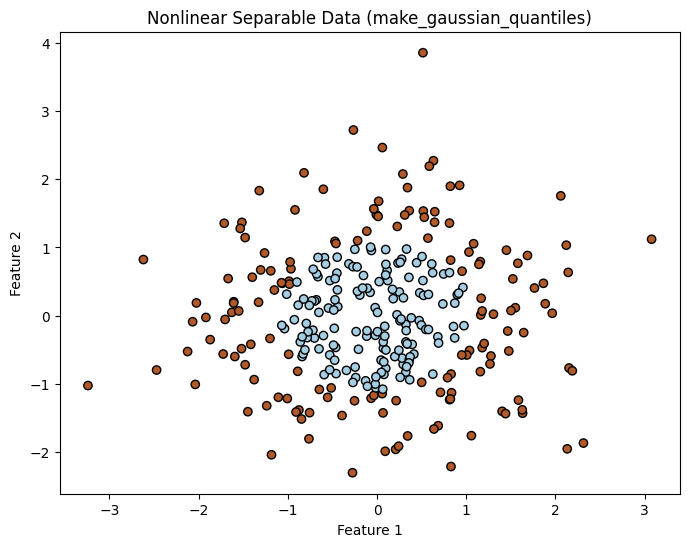

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_gaussian_quantiles
from sklearn.model_selection import train_test_split

np.random.seed(42)
X, y = make_gaussian_quantiles(n_samples=300, n_features=2, n_classes=2,
random_state=42)

#This line was added for better detection in our model
y = np.where(y == 0, -1, 1) #Convert labels to -1,1

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
random_state=42)
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired, marker='o',
edgecolors='k')
plt.title('Nonlinear Separable Data (make_gaussian_quantiles)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

### MADALINE Training Algorithms: MR1 and MR2

MADALINE (Multiple ADAptive LINear Elements) is a type of artificial neural network that employs specific training algorithms to adjust its weights for optimal performance. The two primary algorithms associated with MADALINE are **Madaline Rule I (MR1)** and **Madaline Rule II (MR2)**.

#### Madaline Rule I (MR1)

Introduced in 1962, MR1 was the initial training algorithm for MADALINE networks. Its key characteristics include:

- **Fixed Output Weights:** The weights connecting the hidden ADALINE units to the output unit remain constant during training.

- **Adaptive Hidden Weights:** Only the weights leading into the hidden ADALINE units are adjusted.

- **Majority Voting Mechanism:** The output unit functions based on a majority vote from the hidden units. If the network's output differs from the desired output, the algorithm identifies the minimal number of hidden units that need their outputs changed to correct the error. It then adjusts the weights of those units closest to the decision boundary, adhering to the "minimal disturbance principle."

This approach ensures that the network's behavior is altered as little as possible while correcting errors.

#### Madaline Rule II (MR2)

Developed in 1988 to enhance the training process, MR2 introduces several improvements:

- **Layer-Wide Weight Adjustment:** Unlike MR1, MR2 allows for the adjustment of weights across all layers, including both hidden and output layers.

- **Minimal Disturbance Principle:** The algorithm employs a trial-and-error approach, tentatively flipping the sign of the hidden unit with the lowest confidence in its prediction. If this change reduces the network's error, it is accepted; otherwise, it is reverted. This process ensures that the network remains stable during training, minimizing the unlearning of previously acquired patterns.

- **Efficient Learning:** MR2 has demonstrated the ability to generalize effectively, often requiring training on only a small fraction of the input space to achieve accurate performance.

These advancements make MR2 a more robust and efficient training algorithm for MADALINE networks.

Both MR1 and MR2 have significantly contributed to the development of neural network training methodologies, offering foundational techniques for training MADALINE architectures.


In [ ]:
import warnings
warnings.filterwarnings("ignore")

The algorithm is implemented based on this link:

https://www.geeksforgeeks.org/adaline-and-madaline-network/

In [ ]:
import numpy as np

class Madaline:
    def __init__(self, n_neurons, eta=0.001, epochs=200):
        self.n_neurons = n_neurons
        self.eta = eta
        self.epochs = epochs
        self.weights = None
        self.biases = None

        #Fix the random state
        np.random.seed(42)

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.random.rand(self.n_neurons, n_features)
        self.biases = np.random.rand(self.n_neurons)

        for _ in range(self.epochs):
            for i in range(n_samples):
                # Calculate the net input for each neuron
                net_inputs = np.dot(X[i], self.weights.T) + self.biases

                # Apply the activation function (sign function)
                activations = np.sign(net_inputs)

                # Calculate the output of the Madaline (majority vote)
                output = np.sign(np.sum(activations))

                # MR2 Rule
                if output != y[i]:
                    # Find the neuron with the smallest absolute activation
                    min_activation_idx = np.argmin(np.abs(net_inputs))

                    # Update weights and bias
                    self.weights[min_activation_idx] += self.eta * (y[i] - net_inputs[min_activation_idx]) * X[i]
                    self.biases[min_activation_idx] += self.eta * (y[i] - net_inputs[min_activation_idx])

    def predict(self, X):
        net_inputs = np.dot(X, self.weights.T) + self.biases
        activations = np.sign(net_inputs)
        output = np.sign(np.sum(activations, axis=1))
        return output


### Madaline Class Report

This report describes the `Madaline` class, an implementation of the MADALINE (Multiple ADAptive LINear Elements) neural network.  MADALINE is a type of artificial neural network that uses adaptive linear elements (ADALINEs) in its structure.  This specific implementation uses Madaline Rule II (MR2) for training.


#### Class Structure

The `Madaline` class is initialized with the following parameters:

*   **`n_neurons`**:  The number of neurons in the hidden layer of the Madaline network.
*   **`eta`**: The learning rate, controlling the step size during weight updates (default is 0.001).
*   **`epochs`**: The number of training epochs (default is 200).

The class maintains the following attributes:

*   **`weights`**:  A NumPy array storing the weights connecting the input features to the hidden neurons.
*   **`biases`**: A NumPy array storing the biases for each hidden neuron.


#### Training (fit method)

The `fit` method trains the Madaline network on provided data:

1.  **Initialization:** Randomly initializes the weights and biases.

2.  **Epoch Iteration:** Iterates through the training data for the specified number of epochs.

3.  **Sample Iteration:** Processes each training sample within an epoch.

4.  **Net Input Calculation:**  Calculates the net input for each hidden neuron using the current weights, biases, and input features.

5.  **Activation Function:** Applies the sign activation function to the net inputs to determine the activations of the hidden neurons.

6.  **Output Calculation:** Computes the overall network output as the majority vote of the hidden neuron activations.

7.  **Madaline Rule II (MR2):**
    *   If the network's output does not match the desired output, the algorithm identifies the hidden neuron with the smallest absolute activation.
    *   Updates the weights and bias of the selected neuron using MR2 update rule to minimize the error.

#### Prediction (predict method)

The `predict` method takes a set of input features and predicts the corresponding outputs:

1.  **Net Input Calculation:**  Calculates the net input for each hidden neuron.
2.  **Activation Function:** Applies the sign activation function to get hidden neuron activations.
3.  **Output Calculation:** Computes the overall network output as a majority vote.
4.  **Return:** Returns the predicted output for each input sample.


Now we define a function for visualizing the boundries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def plot_decision_regions(X, y, classifier, resolution=0.02):
    # setup marker generator and color map
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # plot the decision surface
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)
    plt.contourf(xx1, xx2, Z, alpha=0.4, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    # plot class samples
    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0], y=X[y == cl, 1],
                    alpha=0.8, c=cmap(idx),
                    marker=markers[idx], label=cl)


Now we can test the function with various neuron numbers and check the results

Accuracy for 3 neurons: 0.6166666666666667


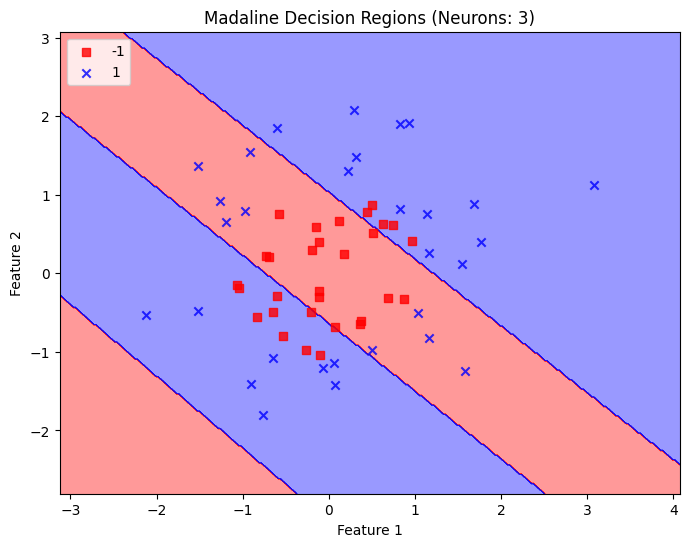

Accuracy for 5 neurons: 0.8666666666666667


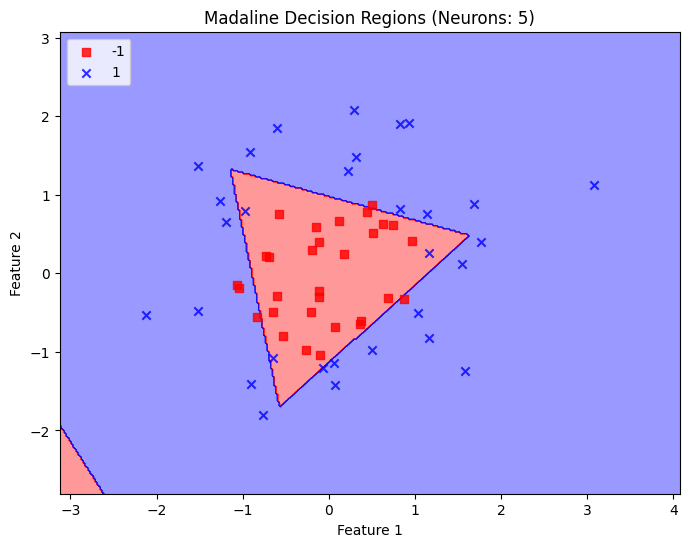

Accuracy for 9 neurons: 0.85


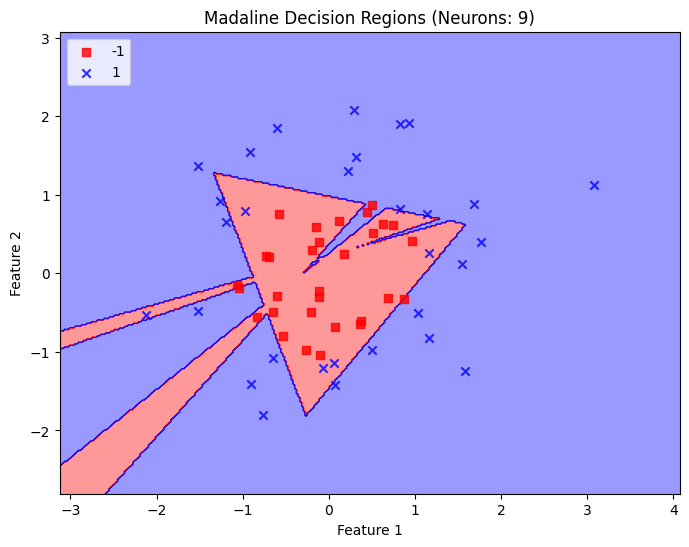

In [ ]:
import matplotlib.pyplot as plt
neuron_numbers = [3, 5, 9]

for n_neurons in neuron_numbers:
    # Train Madaline with different number of neurons
    madaline = Madaline(n_neurons=n_neurons)
    madaline.fit(X_train, y_train)

    # Print the accuracy for each model
    accuracy = np.mean(madaline.predict(X_test) == y_test)
    print(f"Accuracy for {n_neurons} neurons: {accuracy}")

    # Plot decision regions
    plt.figure(figsize=(8, 6))
    plot_decision_regions(X_test, y_test, classifier=madaline)
    plt.title(f'Madaline Decision Regions (Neurons: {n_neurons})')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.legend(loc='upper left')
    plt.show()


### Wine Classification and Synthetic Data Analysis with Adaline and Madaline

This report details experiments conducted on wine classification using the AdalineGD algorithm and synthetic data analysis using the Madaline algorithm.  We investigated the performance of these models under various conditions and explored the impact of model complexity on accuracy.

#### Part 1: Wine Dataset Analysis with AdalineGD

We used the wine dataset, employing the AdalineGD algorithm to classify wine samples into different classes. Our analysis involved detecting each class (0, 1, and 2) individually from the others.  The key observations are:

* **Class Imbalance:** The accuracy of class detection varied across the classes. We observed that class 1 had slightly better detection accuracy than others.  A visualization of class distribution confirmed a minor imbalance, where class 1 had slightly more instances than the other two. This imbalance likely explains the observed differences in accuracy.  The accuracy of class 2 was the lowest.
* **Cost Function Convergence:** Cost function convergence plots were visualized for each class (plots not included in this markdown).

#### Part 2: Synthetic Data Analysis with Madaline

To further investigate the impact of model complexity, we generated synthetic, nonlinearly separable data and applied the Madaline algorithm with varying numbers of neurons in the hidden layer.

* **Model Complexity (Neuron Numbers):** We trained Madaline models with 3, 5, and 9 neurons, visualizing decision boundaries to assess performance.
* **Results:** Different neuron numbers demonstrated varying levels of model complexity:
    * **3 Neurons:** The model was too weak to predict well.
    * **5 Neurons:** Appeared to be the optimal number of neurons for prediction.
    * **9 Neurons:** Indicated overfitting, likely due to the model's increased capacity to learn noise in the training data. The generated decision boundaries for the different neuron counts provided visual confirmation of the model's ability to handle complexity and avoid overfitting.
    * **Accuracy:**  Accuracy scores were calculated for each model to quantify performance.


**Conclusion:**

The experiments demonstrate the impact of model complexity and data characteristics on classifier performance.  Class imbalance in the wine dataset significantly affected AdalineGD accuracy, and the synthetic data analysis revealed an optimal model complexity with Madaline that balanced accuracy and generalization.

# Q3

In [ ]:

import pandas as pd

df = pd.read_csv('/content/Question3.csv')
df.head()  # Print the first few rows of the DataFrame


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [ ]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


## Q3.1

In [ ]:
# count na
print(df.isna().sum())

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


## Q3.2

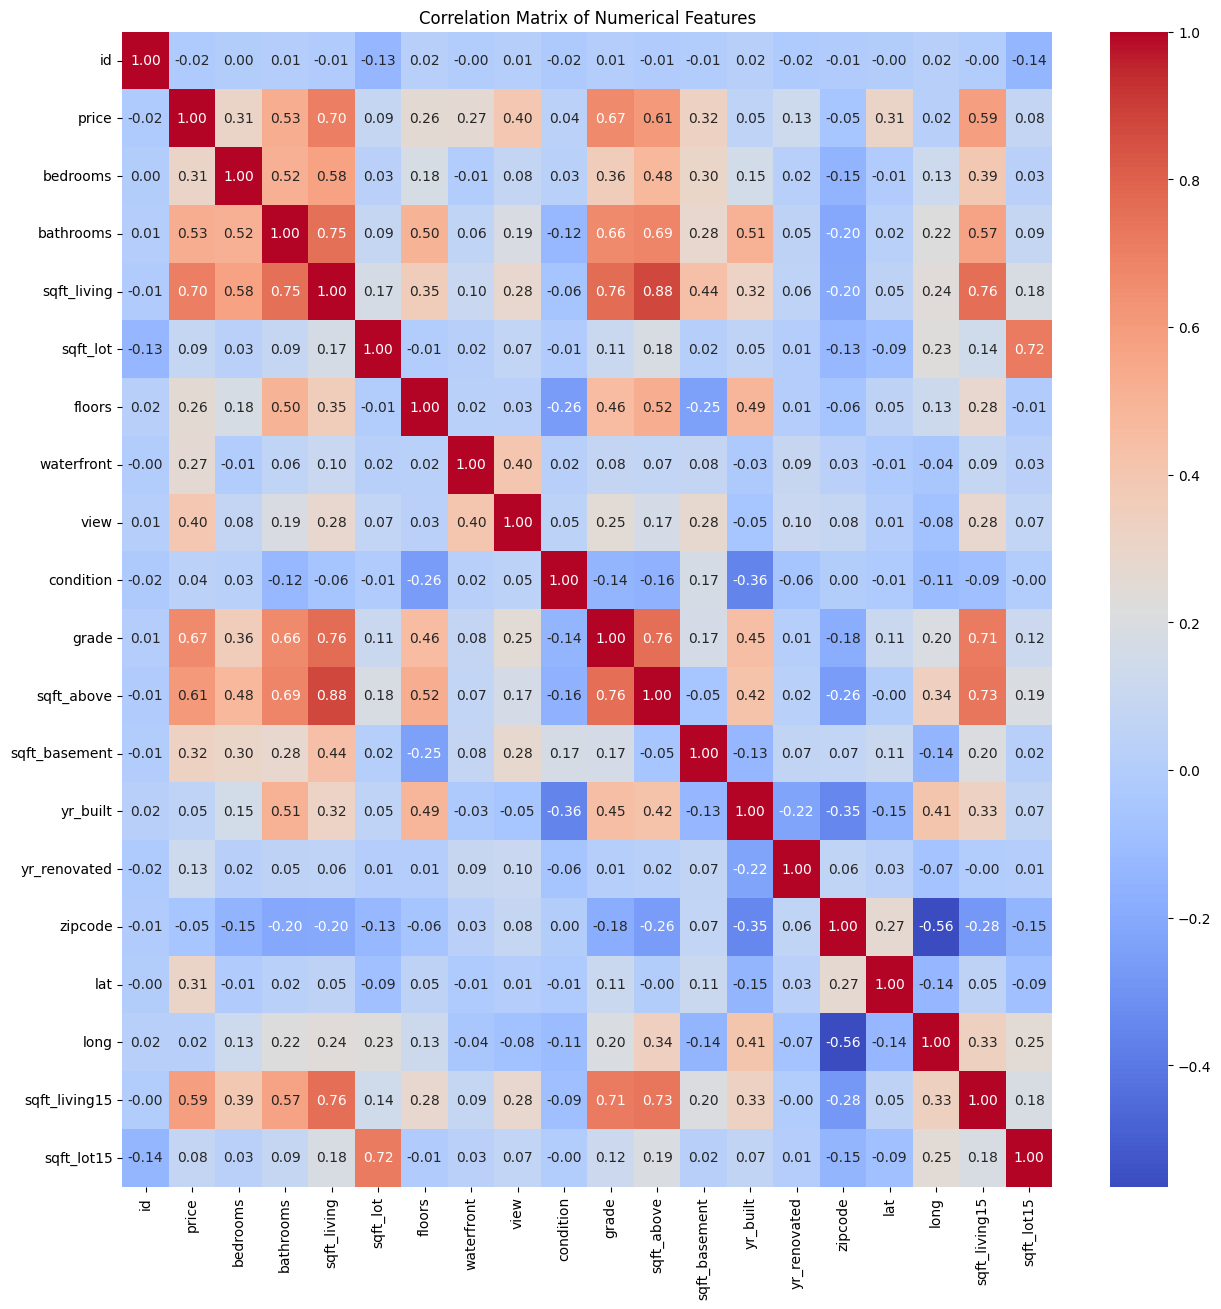

In [ ]:
# corr matrix
# we select only numerical features.
numerical_cols = df.select_dtypes(include=np.number).columns
corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(15, 15))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.show()


sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585379
bathrooms        0.525138
view             0.397293
sqft_basement    0.323816
bedrooms         0.308350
lat              0.307003
waterfront       0.266369
floors           0.256794
yr_renovated     0.126434
sqft_lot         0.089661
sqft_lot15       0.082447
yr_built         0.054012
zipcode          0.053203
condition        0.036362
long             0.021626
id               0.016762
Name: price, dtype: float64


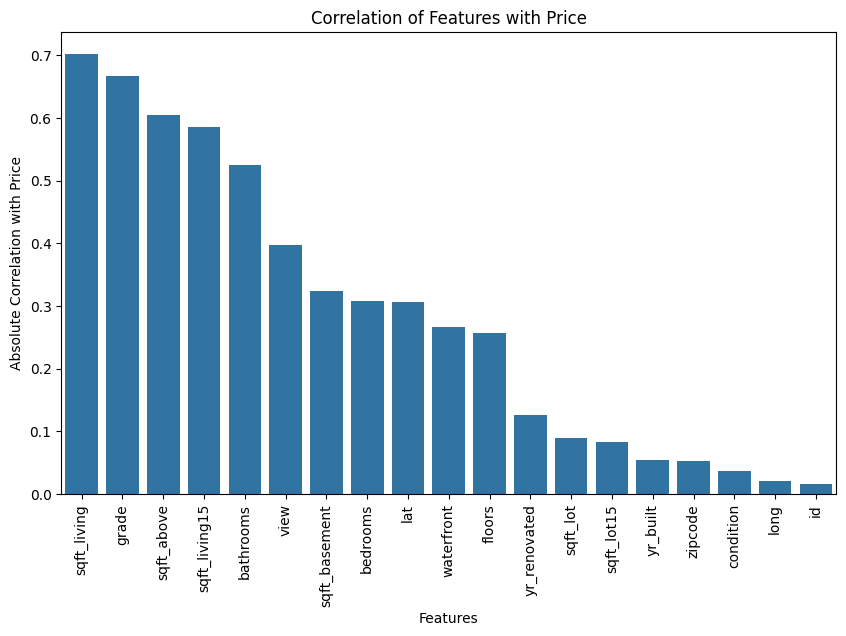

In [ ]:
# which features has higher corr with 'price' ?

# Get the correlation with 'price'
price_corr = corr_matrix['price'].drop('price')

# Sort by absolute correlation
price_corr = price_corr.abs().sort_values(ascending=False)

print(price_corr)

# Plot the correlations
plt.figure(figsize=(10, 6))
sns.barplot(x=price_corr.index, y=price_corr.values)
plt.xticks(rotation=90)
plt.xlabel("Features")
plt.ylabel("Absolute Correlation with Price")
plt.title("Correlation of Features with Price")
plt.show()


## Q3.3

In [ ]:
# plot distribution of 'price'

import plotly.express as px

fig = px.histogram(df, x="price", title="Distribution of Price")
fig.show()


In [ ]:
# plot 'price' vs 'sqft_living' (most correlated feature)

fig = px.scatter(df, x="sqft_living", y="price", title="Price vs Sqft Living" ,  width=800, height=600)
fig.show()


## Q3.4

In [ ]:
# parse 'date' column

df['date'] = pd.to_datetime(df['date'])

df['year'] = df['date'].dt.year

df['month'] = df['date'].dt.month

del df['date']      # delete 'date' column.

df.head()


,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,year,month
0,7129300520,221900.0,3,1.00,1180,5650,1.0,0,0,3,...,0,1955,0,98178,47.5112,-122.257,1340,5650,2014,10
1,6414100192,538000.0,3,2.25,2570,7242,2.0,0,0,3,...,400,1951,1991,98125,47.7210,-122.319,1690,7639,2014,12
2,5631500400,180000.0,2,1.00,770,10000,1.0,0,0,3,...,0,1933,0,98028,47.7379,-122.233,2720,8062,2015,2
3,2487200875,604000.0,4,3.00,1960,5000,1.0,0,0,5,...,910,1965,0,98136,47.5208,-122.393,1360,5000,2014,12
4,1954400510,510000.0,3,2.00,1680,8080,1.0,0,0,3,...,0,1987,0,98074,47.6168,-122.045,1800,7503,2015,2


In [ ]:
# train test split
from sklearn.model_selection import train_test_split

# Separate features (X) and target variable (y)
X = df.drop('price', axis=1)  # Features
y = df['price']  # Target variable

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [ ]:
# Use MinMaxScaler

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [ ]:
print(X_train_scaled.shape, X_test_scaled.shape, y_train.shape, y_test.shape)

(16209, 21) (5404, 21) (16209,) (5404,)


## Q3.5 , Q3.6 , Q3.7

In [ ]:
# 2 MLP: 1 hidden layer and 2 hidden layer to predict house price


# Define the MLP model with one hidden layer
model_1_hidden = keras.Sequential([
    InputLayer(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation='relu'),
    Dense(1)  # Output layer for regression
])

model_1_hidden.compile(optimizer='nadam', loss='mae', metrics=['mae' , 'mse'])
history_1 = model_1_hidden.fit(X_train_scaled, y_train, epochs=500, batch_size=128, validation_split=0.2, verbose=0)
loss_1, mae_1 , mse_1 = model_1_hidden.evaluate(X_test_scaled, y_test, verbose=0)

print("MLP with 1 hidden layer:")
print(f"Loss: {loss_1}, MAE: {mae_1}")

MLP with 1 hidden layer:
Loss: 194132.625, MAE: 194132.625


In [ ]:
# Define the MLP model with two hidden layers
model_2_hidden = keras.Sequential([
    InputLayer(shape=(X_train_scaled.shape[1],)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1)
])

model_2_hidden.compile(optimizer='nadam', loss='mae', metrics=['mae' , 'mse'])
history_2 = model_2_hidden.fit(X_train_scaled, y_train, epochs=500, batch_size=128, validation_split=0.2, verbose=0)
loss_2, mae_2 , mse_2= model_2_hidden.evaluate(X_test_scaled, y_test, verbose=0)
print("\nMLP with 2 hidden layers:")
print(f"Loss: {loss_2}, MAE: {mae_2}")


MLP with 2 hidden layers:
Loss: 111234.5703125, MAE: 111234.5703125


Nadam shows better performance in our tests and analysis, So we decide to use Nadam as optimizer. For loss function, we choose "MAE" (Mean Absolute Error) over "MSE"(Mean Squared Error), In case the data contains outliers! (which you can observe from the 'price' histogram plot, which is very right-tailed, showing we have a lot of outliers with a high price beyond the valid quantiles)

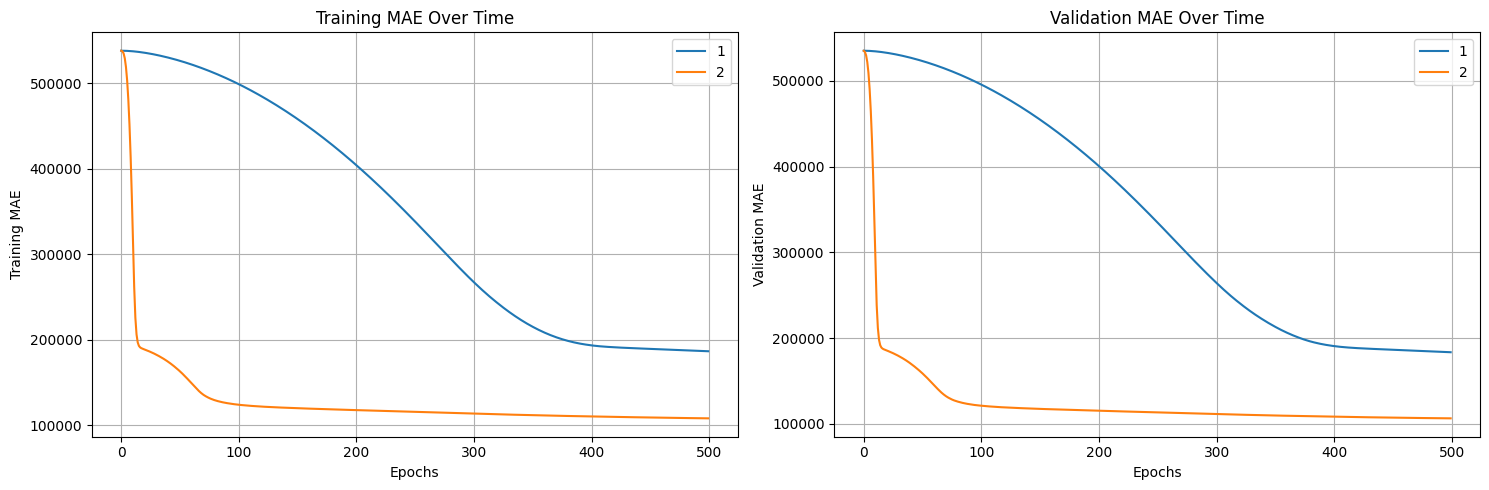

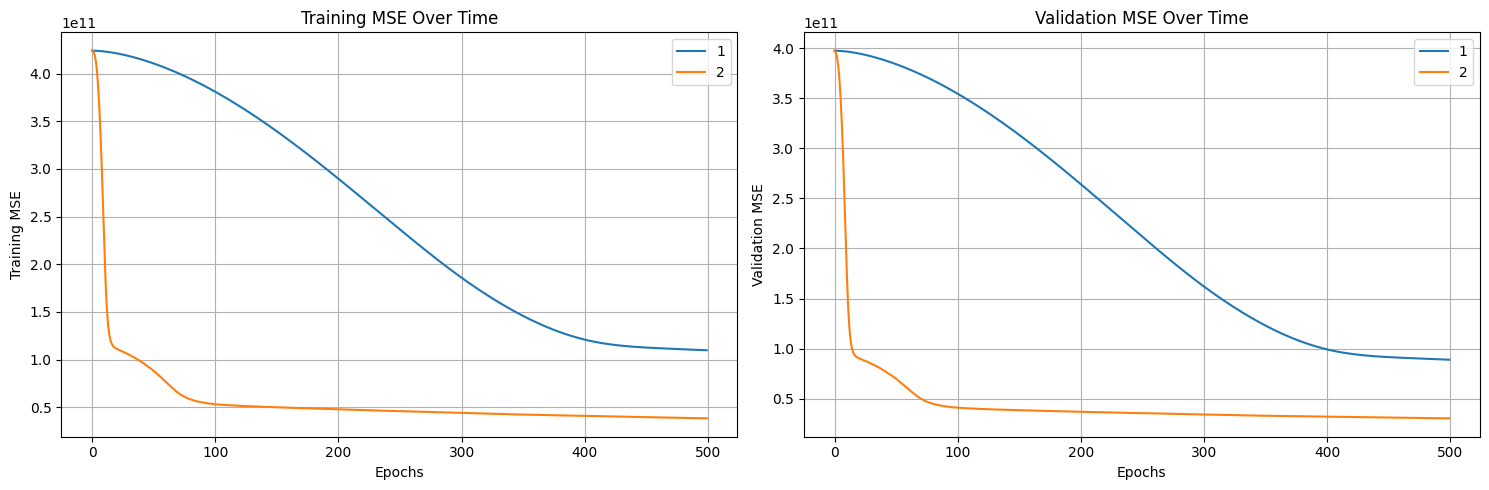

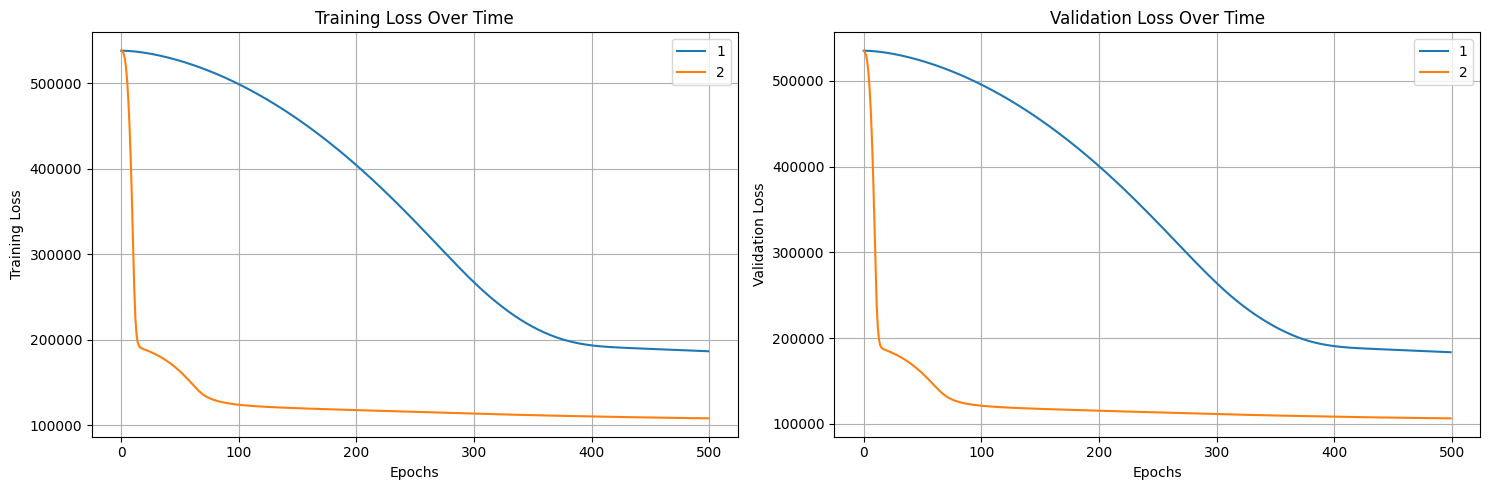

In [ ]:
plot([history_1 , history_2] , "mae" , "val_mae" , "Training MAE" , "Validation MAE" , ['1' , '2'])
plot([history_1 , history_2] , "mse" , "val_mse" , "Training MSE" , "Validation MSE" , ['1' , '2'])
plot([history_1 , history_2] , "loss" , "val_loss" , "Training Loss" , "Validation Loss", ['1' , '2'])    # since loss = mae , this plot is the same as the first plot.(we just include it in case we change our main loss function)


Since the first model is **weaker (it has 1 hidden layer)**, it takes much more time to capture and learn the meaningful features of the data.
And that is why the first model reaches a state around epoch 350 that the second model had already reached by approximately epoch 20.

We could further train our models for larger epochs to see if the first model reaches a perfromance close to first model or not.(hypotesis: it won't)

For the last part, we randomly choose 5 samples form our test set and evaluate both models on them.

In [ ]:
# select 5 different random samples from test set and predict using both regressor models

import random

# Select 5 random samples from the test set
random_indices = random.sample(range(len(X_test_scaled)), 5)
random_samples = X_test_scaled[random_indices]
random_targets = y_test.iloc[random_indices]

# Predict using both models
predictions_model_1 = model_1_hidden.predict(random_samples)
predictions_model_2 = model_2_hidden.predict(random_samples)


# Print or further process the predictions and actual values
for i in range(5):
    print(f"Sample {i+1}:")
    print(f"  Actual Price: {random_targets.iloc[i]}")
    print(f"  Model 1 Prediction: {predictions_model_1[i][0]}")
    print(f"  Model 2 Prediction: {predictions_model_2[i][0]}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step
Sample 1:
  Actual Price: 345000.0
  Model 1 Prediction: 327322.09375
  Model 2 Prediction: 268353.71875
Sample 2:
  Actual Price: 400000.0
  Model 1 Prediction: 401910.09375
  Model 2 Prediction: 341763.34375
Sample 3:
  Actual Price: 687500.0
  Model 1 Prediction: 470025.875
  Model 2 Prediction: 669415.375
Sample 4:
  Actual Price: 401500.0
  Model 1 Prediction: 465982.78125
  Model 2 Prediction: 457548.59375
Sample 5:
  Actual Price: 152000.0
  Model 1 Prediction: 358564.21875
  Model 2 Prediction: 149710.5


In samples 1 and 2, the first model predicts a closer price, while in the rest, the second model (2 hidden layer) predicts much closer price.